In [1]:
import numpy as np
from matplotlib import pyplot as plt
from cycler import cycler
plt.rc('axes', prop_cycle=cycler(color=['0.0', '0.4', '0.8']))
import matplotlib; matplotlib.rcParams.update({'font.size': 18})

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
from IPython.display import HTML
import course_helpers as chh
apply_beamer_theme(
    "madrid", skip_font_download=True, author="Robert Pettis", date="Fall 2026",
    show_slide_number=True, cell_tags=True, notebook_path="14-Recurrent-Networks-and-LSTM.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 70 cell(s):
 cell_index   slide_id                                  tags
          9  slide-1-0 slide_hide_prompt, slide_remove_input
         11  slide-1-1 slide_hide_prompt, slide_remove_input
         13  slide-1-2 slide_hide_prompt, slide_remove_input
         16  slide-1-4 slide_hide_prompt, slide_remove_input
         18  slide-1-5 slide_hide_prompt, slide_remove_input
         21  slide-2-1 slide_hide_prompt, slide_remove_input
         23  slide-2-2 slide_hide_prompt, slide_remove_input
         25  slide-2-3 slide_hide_prompt, slide_remove_input
         27  slide-2-4 slide_hide_prompt, slide_remove_input
         29  slide-2-5 slide_hide_prompt, slide_remove_input
         31  slide-2-6 slide_hide_prompt, slide_remove_input
         33  slide-2-7 slide_hide_prompt, slide_remove_input
         35  slide-2-8 slide_hide_prompt, slide_remove_input
         37  slide-2-9 slide_hide_prompt, slide_remove_input
         39 slide-2-10 slide_hide_prompt, sli

In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

In [4]:
# One place that knows the weights, the two companies, and how to draw the
# recurrent network, the LSTM unit and the unrolled chains. Every slide below
# supplies only its own numbers.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pywrangling.graphing_functions import set_top_ylabel
import course_helpers as chh

# ------------------------------------------------------------------ numbers
# RNN: input weight 1.8, feedback -0.5, output weight 1.1. Older printings
# have 1.8 on the output too; the published errata put a 1.1 on one of them.
W1, B1, W2, W3, B2 = 1.8, 0.0, -0.5, 1.1, 0.0

# LSTM: (short-term memory weight, input weight, bias)
FORGET = (2.70, 1.63, 1.62)      # % Long-Term To Remember
REMEMBER = (2.00, 1.65, 0.62)    # % Potential Memory To Remember
POTENTIAL = (1.41, 0.94, -0.32)  # Potential Long-Term Memory (tanh)
OUTPUT = (4.38, -0.19, 0.59)     # % Potential Memory To Remember (output gate)

COMPANY_A = [0.0, 0.5, 0.25, 1.0]
COMPANY_B = [1.0, 0.5, 0.25, 1.0]

BLUE = "#2A6FBF"      # inputs, and the sigmoid boxes
GREEN = "#2E8B57"     # outputs, and the long-term memory line
PINK = "#C2185B"      # the short-term memory line
ORANGE = "#E08A1E"    # tanh boxes
GATE_FILL = {"forget": "#DCEBF7", "remember": "#E3F1E3", "potential": "#FBEBD3",
             "output": "#EDE3F3", "final": "#F8E1EA"}
HOT = "#B3121F"       # the value being worked on


def relu(x):
    return max(0.0, x)


def sigmoid(x):
    return float(np.exp(x) / (np.exp(x) + 1))


def rnn_run(days):
    """Run the unrolled RNN. Returns one dict per day with the sum, the ReLU
       output, the feedback carried to the next day and the predicted value."""
    out, carry = [], 0.0
    for x in days:
        s = x * W1 + carry + B1
        a = relu(s)
        out.append(dict(x=x, carry_in=carry, sum=s, act=a, pred=a * W3 + B2, carry_out=a * W2))
        carry = a * W2
    return out


def lstm_step(ltm, stm, x):
    """One pass through the LSTM unit, every intermediate value kept."""
    r = dict(ltm_in=ltm, stm_in=stm, x=x)
    r["f_sum"] = FORGET[0] * stm + FORGET[1] * x + FORGET[2]
    r["f"] = sigmoid(r["f_sum"])
    r["ltm_kept"] = ltm * r["f"]
    r["r_sum"] = REMEMBER[0] * stm + REMEMBER[1] * x + REMEMBER[2]
    r["r"] = sigmoid(r["r_sum"])
    r["p_sum"] = POTENTIAL[0] * stm + POTENTIAL[1] * x + POTENTIAL[2]
    r["p"] = float(np.tanh(r["p_sum"]))
    r["added"] = r["r"] * r["p"]
    r["ltm"] = r["ltm_kept"] + r["added"]
    r["o_sum"] = OUTPUT[0] * stm + OUTPUT[1] * x + OUTPUT[2]
    r["o"] = sigmoid(r["o_sum"])
    r["tanh_ltm"] = float(np.tanh(r["ltm"]))
    r["stm"] = r["o"] * r["tanh_ltm"]
    return r


def as_printed(r):
    """The page's numbers: each product is taken from the rounded factors,
       so 0.99 x 0.97 prints as 0.96 though the unrounded product is 0.953."""
    p = {k: round(v, 2) for k, v in r.items()}
    p["added"] = round(p["r"] * p["p"], 2)
    p["ltm_kept"] = round(r["ltm_in"] * round(r["f"], 3), 2)
    p["ltm"] = round(p["ltm_kept"] + p["added"], 2)
    p["tanh_ltm"] = round(float(np.tanh(p["ltm"])), 2)
    p["stm"] = round(p["o"] * p["tanh_ltm"], 2)
    p["f"] = r["f"]
    return p


def lstm_run(days, ltm=0.0, stm=0.0):
    out = []
    for x in days:
        r = lstm_step(ltm, stm, x)
        out.append(r)
        ltm, stm = r["ltm"], r["stm"]
    return out


# ------------------------------------------------------------------ helpers
def frame(figsize, xlim, ylim, dpi=110):
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax.axis("off")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    return fig, ax


def note(ax, x, y, text, fs=10.0, ha="left", va="center", color=None, weight=None, z=9):
    ax.text(x, y, text, ha=ha, va=va, fontsize=fs, linespacing=1.3,
            color=color or chh.INK, weight=weight, zorder=z)


def arrow(ax, a, b, color=None, lw=1.6, style="-|>", rad=0.0, z=4):
    ax.annotate("", xy=b, xytext=a, zorder=z,
                arrowprops=dict(arrowstyle=style, color=color or chh.INK, lw=lw,
                                connectionstyle="arc3,rad=%.2f" % rad,
                                shrinkA=0, shrinkB=0, mutation_scale=12))


def line(ax, pts, color, lw=2.0, z=3):
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=color, lw=lw, zorder=z, solid_capstyle="round")


def tag(ax, x, y, text, color=None, fs=9.0, edge="#9AA0B0", fill="white", hot=False):
    """A small boxed label such as x 1.8 or + 0.0, centred on (x, y)."""
    ax.text(x, y, text, ha="center", va="center", fontsize=fs,
            color=HOT if hot else (color or chh.INK), weight="bold" if hot else None,
            zorder=7, bbox=dict(boxstyle="square,pad=0.22", facecolor=fill,
                                edgecolor=HOT if hot else edge, lw=1.4 if hot else 0.9))


def node_box(ax, x, y, w, h, color, text="", fs=11, lw=2.0, fill="white", tc=None, weight=None):
    """A square box centred on (x, y): inputs, outputs, activation functions."""
    ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, facecolor=fill,
                               edgecolor=color, lw=lw, zorder=5))
    if text != "":
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=6,
                color=tc or chh.INK, weight=weight)


def act_box(ax, x, y, kind, s=0.9, color=None):
    """An activation function drawn as a box holding its curve."""
    color = color or {"relu": BLUE, "sigmoid": BLUE, "tanh": ORANGE}[kind]
    node_box(ax, x, y, s, s, color)
    t = np.linspace(-1, 1, 60)
    if kind == "relu":
        v = np.where(t < 0.1, -0.7, -0.7 + (t - 0.1) * 1.5)
    elif kind == "sigmoid":
        v = 1.4 / (1 + np.exp(-6 * t)) - 0.7
    else:
        v = 0.7 * np.tanh(3 * t)
    ax.plot(x + t * s * 0.36, y + v * s * 0.36, color=chh.INK, lw=1.6, zorder=6)


def gate_fmt(v):
    """Three places when two would round a gate up to 1.00."""
    return fmt(v, 3) if fmt(v) == "1.00" else fmt(v)


def fmt(v, d=2):
    s = ("%." + str(d) + "f") % v
    return "0" + s[2:] if s.startswith("-0") and float(s) == 0 else s


# ------------------------------------------------------------------ RNN
def rnn_copy(ax, x0, y, label="Input", value=None, out_label=None, out_value=None,
             fade_output=False, feedback_out=True, carry_in=None, show_sum=None,
             show_act=None, hot=(), w3=W3, w1=W1, fade_all=False, sum_above=False, act_name=None):
    """One copy of the RNN, drawn left to right from the input box at (x0, y).
       Returns the coordinates the feedback arrow leaves from and arrives at."""
    a = 0.3 if fade_all else 1.0
    col = lambda c: c if not fade_all else "#C8C8C8"
    node_box(ax, x0, y, 0.9, 0.9, col(BLUE), "" if value is None else fmt(value, 2).rstrip("0").rstrip(".") if value not in (0, 1) else "%d" % value, fs=11)
    note(ax, x0 - 0.45, y + 0.72, label, fs=10, color=col(chh.INK))
    tag(ax, x0 + 1.15, y, "x %.1f" % w1, hot="w1" in hot)
    arrow(ax, (x0 + 1.6, y), (x0 + 2.15, y), color=col(BLUE))
    note(ax, x0 + 2.5, y, "Sum", fs=10, ha="center", color=col(chh.INK))
    tag(ax, x0 + 3.35, y, "+ %.1f" % B1, hot="b1" in hot)
    arrow(ax, (x0 + 3.85, y), (x0 + 4.3, y), color=col(BLUE))
    act_box(ax, x0 + 4.8, y, "relu", color=col(BLUE))
    tag(ax, x0 + 6.0, y, "x %.1f" % w3, hot="w3" in hot)
    arrow(ax, (x0 + 6.45, y), (x0 + 7.0, y), color=col(BLUE))
    note(ax, x0 + 7.35, y, "Sum", fs=10, ha="center", color=col(chh.INK))
    tag(ax, x0 + 8.2, y, "+ %.1f" % B2, hot="b2" in hot)
    arrow(ax, (x0 + 8.7, y), (x0 + 9.15, y), color=col(GREEN))
    node_box(ax, x0 + 9.6, y, 0.9, 0.9, col(GREEN) if not fade_output else "#BBBBBB",
             "" if out_value is None else fmt(out_value), fs=10.5,
             tc=HOT if out_value is not None else None, weight="bold" if out_value is not None else None)
    if out_label:
        note(ax, x0 + 9.6, y + 0.75, out_label, fs=9, ha="center",
             color="#999999" if fade_output else chh.INK)
    if show_sum is not None:
        note(ax, x0 + 2.5, y + (0.45 if sum_above else -0.45), fmt(show_sum), fs=10, ha="center",
             color=HOT, weight="bold")
    if show_act is not None:
        note(ax, x0 + 5.3, y + 0.5, ("%s = %s" % (act_name, fmt(show_act))) if act_name else fmt(show_act),
             fs=10, ha="left", color=HOT, weight="bold")
    if carry_in is not None:
        note(ax, x0 + 1.95, y + 0.62, "+ (%s)" % fmt(carry_in), fs=9.5, ha="center", color=HOT, weight="bold")
    return (x0 + 4.8, y - 0.45), (x0 + 2.5, y + 0.25)


def rnn_rolled(ax, x0=0.6, y=0.0, hot=(), value=None, out_value=None, **kw):
    """The RNN with its feedback loop, as on the first page."""
    src, dst = rnn_copy(ax, x0, y, value=value, out_label=kw.pop("out_label", "Output"),
                        out_value=out_value, hot=hot, **kw)
    # loop from below the ReLU back into the first Sum
    ax.annotate("", xy=(x0 + 2.5, y - 0.25), xytext=(x0 + 4.8, y - 0.45), zorder=4,
                arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.8,
                                connectionstyle="arc3,rad=-1.1", mutation_scale=12))
    tag(ax, x0 + 4.75, y - 1.45, "x %.1f" % W2, hot="w2" in hot)


def rnn_unrolled(ax, days, x0=0.6, y0=0.0, gap=2.1, labels=None, values=True, hot=(),
                 show_math=False, fade_upper_outputs=True):
    """The RNN unrolled once per day, copies stacked downward, the feedback
       running from each copy's ReLU into the next copy's Sum."""
    run = rnn_run(days)
    n = len(days)
    labels = labels or default_day_labels(n)
    for k, d in enumerate(run):
        y = y0 - k * gap
        last = k == n - 1
        rnn_copy(ax, x0, y, label=labels[k], value=d["x"] if values else None, act_name="y%d" % (k + 1),
                 out_label=("Predicted value for Tomorrow" if last else ("Predicted value for %s" % labels[k + 1])),
                 out_value=d["pred"] if (show_math and last) else None,
                 fade_output=(not last) and fade_upper_outputs,
                 carry_in=d["carry_in"] if (show_math and k > 0) else None,
                 show_sum=d["sum"] if show_math else None,
                 show_act=d["act"] if show_math else None, hot=hot)
        if not last:
            ya, yb = y - 0.45, y - gap + 0.25
            ax.annotate("", xy=(x0 + 2.5, yb), xytext=(x0 + 4.8, ya), zorder=4,
                        arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.8,
                                        connectionstyle="arc3,rad=-0.35", mutation_scale=12))
            tag(ax, x0 + 4.3, y - gap / 2 - 0.05, "x %.1f" % W2, hot="w2" in hot)
            if show_math:
                note(ax, x0 + 5.3, y - gap / 2 - 0.05, "%s x %.1f = %s" % (fmt(d["act"]), W2, fmt(d["carry_out"])),
                     fs=9.5, color=HOT, weight="bold")
    return run


def default_day_labels(n):
    if n == 2:
        return ["Yesterday", "Today"]
    if n == 3:
        return ["Day Before Yesterday", "Yesterday", "Today"]
    return ["Day %d" % (k + 1) for k in range(n)]


def price_panel(ax, x0, y0, prices, w=2.2, h=2.0, labels=None, tomorrow=None,
                colors=None, fs=8.5):
    """A small price chart in data units: blue dots for the days we know, a
       green dot for tomorrow."""
    n = len(prices) + (tomorrow is not None)
    ax.plot([x0, x0], [y0, y0 + h], color=chh.INK, lw=1.2, zorder=3)
    ax.plot([x0, x0 + w], [y0, y0], color=chh.INK, lw=1.2, zorder=3)
    for v, t in ((0, "0"), (0.5, "0.5"), (1, "1")):
        note(ax, x0 - 0.08, y0 + v * h * 0.85, t, fs=fs, ha="right")
    xs = [x0 + 0.3 + k * (w - 0.5) / max(n - 1, 1) for k in range(n)]
    pts = list(prices) + ([tomorrow] if tomorrow is not None else [])
    ys = [y0 + p * h * 0.85 for p in pts]
    ax.plot(xs, ys, color="#888888", lw=1.0, ls=(0, (2, 2)), zorder=3)
    for k, (x, yy) in enumerate(zip(xs, ys)):
        c = GREEN if (tomorrow is not None and k == n - 1) else BLUE
        if colors:
            c = colors[k]
        ax.scatter([x], [yy], s=70, color=c, edgecolor="white", zorder=5)
    if labels:
        for x, t in zip(xs, labels):
            note(ax, x, y0 - 0.3, t, fs=fs, ha="center")
    return xs, ys


# ------------------------------------------------------------------ LSTM unit
# x centres of the five blocks and the shared rows
LX = {"forget": 4.6, "remember": 8.2, "potential": 11.8, "output": 15.4, "final": 18.8}
Y_LTM, Y_ACT, Y_BIAS, Y_SUM, Y_STM, Y_IN, Y_INPUT = 8.2, 6.3, 5.25, 4.45, 3.3, 2.35, 0.7
MX = 10.0             # where % Potential Memory times Potential Long-Term Memory joins the line
STAGES = ("forget", "remember", "potential", "output", "final")


def lstm_unit(ax, ltm=None, stm=None, x=None, show=(), focus=None, dim=(), vals=True,
              labels=False, gates=False):
    """The LSTM unit as on page 163. show: which stages print their worked
       numbers. focus: one stage drawn in full colour while the rest fade.
       dim: stages faded regardless. ltm, stm, x: the values coming in."""
    r = lstm_step(ltm, stm, x) if None not in (ltm, stm, x) else None

    keep = (focus,) if isinstance(focus, str) else focus

    def faded(stage):
        return (keep is not None and stage not in keep) or stage in dim

    def c(stage, colr):
        return "#CFCFCF" if faded(stage) else colr

    # block backgrounds
    for st in STAGES:
        cx = LX[st]
        ax.add_patch(plt.Rectangle((cx - 1.55, Y_IN - 0.55), 3.1, Y_ACT - Y_IN + 1.25,
                                   facecolor="#F6F6F6" if faded(st) else GATE_FILL[st],
                                   edgecolor="#BBBBBB", lw=0.8, ls=(0, (2, 2)), zorder=1))
    # long-term memory line
    line(ax, [(-0.4, Y_LTM), (LX["forget"] - 0.25, Y_LTM)], GREEN, lw=2.6)
    line(ax, [(LX["forget"] + 0.25, Y_LTM), (MX - 0.3, Y_LTM)], GREEN, lw=2.6)
    line(ax, [(MX + 0.45, Y_LTM), (21.6, Y_LTM)], GREEN, lw=2.6)
    arrow(ax, (21.2, Y_LTM), (21.8, Y_LTM), color=GREEN, lw=2.6)
    ax.text(LX["forget"], Y_LTM, "x", ha="center", va="center", fontsize=15, weight="bold", zorder=8,
            bbox=dict(boxstyle="circle,pad=0.05", facecolor="white", edgecolor="none"))
    ax.text(MX + 0.1, Y_LTM, "Sum", ha="center", va="center", fontsize=10.5, weight="bold", zorder=8,
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
    note(ax, -0.4, Y_LTM + 0.25, "Long-Term\nMemory", fs=10, va="bottom", color=GREEN, weight="bold")
    # short-term memory line, enters every block
    line(ax, [(-0.4, Y_STM), (LX["output"] + 0.4, Y_STM)], PINK, lw=2.4)
    note(ax, -0.4, Y_STM + 0.22, "Short-Term\nMemory", fs=10, va="bottom", color=PINK, weight="bold")
    # input line
    node_box(ax, 3.1, Y_INPUT, 0.9, 0.9, BLUE, "" if x is None else fmt(x, 2).rstrip("0").rstrip(".") if x not in (0, 1) else "%d" % x)
    note(ax, 3.1, Y_INPUT - 0.75, "Input", fs=10, ha="center")
    line(ax, [(3.1, Y_INPUT + 0.45), (3.1, Y_INPUT + 0.85), (LX["output"] + 0.4, Y_INPUT + 0.85)], chh.INK, lw=1.4)
    for st, (ws, wi, b) in zip(("forget", "remember", "potential", "output"),
                               (FORGET, REMEMBER, POTENTIAL, OUTPUT)):
        cx = LX[st]
        kind = "tanh" if st == "potential" else "sigmoid"
        # short-term memory weight on the left, input weight below
        line(ax, [(cx - 0.75, Y_STM), (cx - 0.75, Y_SUM)], c(st, PINK), lw=1.4)
        arrow(ax, (cx - 0.75, Y_SUM), (cx - 0.35, Y_SUM), color=c(st, PINK), lw=1.4)
        tag(ax, cx - 0.95, Y_STM + 0.5, "x %.2f" % ws, color=c(st, chh.INK))
        line(ax, [(cx, Y_INPUT + 0.85), (cx, Y_SUM - 0.25)], c(st, chh.INK), lw=1.4)
        tag(ax, cx + 0.15, Y_IN, "x %.2f" % wi, color=c(st, chh.INK))
        note(ax, cx, Y_SUM, "Sum", fs=9.5, ha="center", color=c(st, chh.INK))
        arrow(ax, (cx, Y_SUM + 0.25), (cx, Y_ACT - 0.45), color=c(st, chh.INK), lw=1.4)
        tag(ax, cx + 0.62, Y_BIAS, ("+ %.2f" % b).replace("+ -", "- "), color=c(st, chh.INK))
        act_box(ax, cx, Y_ACT, kind, color=c(st, BLUE if kind == "sigmoid" else ORANGE))
    # forget gate up to the x on the long-term line
    cxf = LX["forget"]
    arrow(ax, (cxf, Y_ACT + 0.45), (cxf, Y_LTM - 0.3), color=c("forget", BLUE), lw=1.6)
    # remember and potential meet at an x, then up to the Sum
    mx, my = MX, Y_ACT + 0.95
    line(ax, [(LX["remember"], Y_ACT + 0.45), (LX["remember"], my), (mx - 0.25, my)], c("remember", BLUE), lw=1.6)
    line(ax, [(LX["potential"], Y_ACT + 0.45), (LX["potential"], my), (mx + 0.25, my)], c("potential", ORANGE), lw=1.6)
    note(ax, mx, my, "x", fs=15, ha="center", weight="bold", color=c("remember", chh.INK))
    arrow(ax, (mx, my + 0.25), (mx, Y_LTM - 0.3), color=c("remember", chh.INK), lw=1.6)
    # output: the new long-term memory drops into a tanh, times the output gate
    fx = LX["final"]
    arrow(ax, (fx, Y_LTM), (fx, Y_ACT + 0.45), color=c("final", GREEN), lw=1.6)
    act_box(ax, fx, Y_ACT, "tanh", color=c("final", ORANGE))
    ox, oy = fx, Y_SUM
    arrow(ax, (fx, Y_ACT - 0.45), (ox, oy + 0.28), color=c("final", ORANGE), lw=1.6)
    line(ax, [(LX["output"], Y_ACT + 0.45), (LX["output"], Y_ACT + 0.85), (16.9, Y_ACT + 0.85), (16.9, oy)], c("output", BLUE), lw=1.6)
    arrow(ax, (16.9, oy), (ox - 0.28, oy), color=c("output", BLUE), lw=1.6)
    note(ax, ox, oy, "x", fs=15, ha="center", weight="bold", color=c("final", chh.INK))
    line(ax, [(ox, oy - 0.28), (ox, Y_STM - 0.0), (21.2, Y_STM)], c("final", PINK), lw=2.4)
    arrow(ax, (21.2, Y_STM), (21.8, Y_STM), color=c("final", PINK), lw=2.4)
    note(ax, 21.8, Y_STM - 0.45, "New Short-Term\nMemory", fs=9.5, ha="right", va="top", color=PINK, weight="bold")
    note(ax, 21.8, Y_LTM - 0.45, "New Long-Term\nMemory", fs=9.5, ha="right", va="top", color=GREEN, weight="bold")
    if ltm is not None:
        note(ax, -0.4, Y_LTM - 0.42, fmt(ltm), fs=11, weight="bold", color=GREEN)
    if stm is not None:
        note(ax, -0.4, Y_STM - 0.42, fmt(stm), fs=11, weight="bold", color=PINK)
    if labels:
        for st, txt in (("forget", "% Long-Term\nTo Remember"), ("remember", "% Potential Memory\nTo Remember"),
                        ("potential", "Potential\nLong-Term Memory"), ("output", "% Potential Memory\nTo Remember"),
                        ("final", "Potential\nShort-Term Memory")):
            note(ax, LX[st], Y_IN - 0.95, txt, fs=8.5, ha="center", va="top",
                 color="#BBBBBB" if faded(st) else chh.INK)
    if gates:
        for sts, name in ((("forget",), "Forget Gate"), (("remember", "potential"), "Input Gate"),
                          (("output", "final"), "Output Gate")):
            x0 = LX[sts[0]] - 1.7
            x1 = LX[sts[-1]] + 1.7
            hot = gates is True or name in gates
            ax.add_patch(plt.Rectangle((x0, Y_IN - 0.7), x1 - x0, Y_ACT - Y_IN + 1.55, fill=False,
                                       edgecolor=HOT if hot else "#DDDDDD", lw=2.0 if hot else 1.0,
                                       ls=(0, (4, 3)), zorder=2))
            note(ax, (x0 + x1) / 2, Y_INPUT - 1.05, name, fs=11, ha="center", va="top",
                 color=HOT if hot else "#BBBBBB", weight="bold")
    if r is None or not vals:
        return r
    r = as_printed(r)
    # worked numbers, printed beside the part they belong to
    def hotnote(px, py, t, ha="left"):
        note(ax, px, py, t, fs=10.5, ha=ha, color=HOT, weight="bold", z=10)
    show = expand_show(show)
    if "f_sum" in show:
        hotnote(LX["forget"] + 0.48, Y_SUM - 0.05, fmt(r["f_sum"]))
    if "f" in show:
        hotnote(LX["forget"] + 0.55, Y_ACT + 0.75, gate_fmt(r["f"]))
    if "kept" in show:
        hotnote(LX["forget"] + 0.35, Y_LTM + 0.45, fmt(r["ltm_kept"]))
    if "r_sum" in show:
        hotnote(LX["remember"] + 0.48, Y_SUM - 0.05, fmt(r["r_sum"]))
    if "r" in show:
        hotnote(LX["remember"] - 0.6, Y_ACT + 1.25, fmt(r["r"]), ha="center")
    if "p_sum" in show:
        hotnote(LX["potential"] + 0.48, Y_SUM - 0.05, fmt(r["p_sum"]))
    if "p" in show:
        hotnote(LX["potential"] + 0.6, Y_ACT + 1.25, fmt(r["p"]), ha="center")
    if "added" in show:
        hotnote(mx + 0.3, my + 0.6, fmt(r["added"]))
    if "ltm" in show:
        hotnote(MX + 0.6, Y_LTM + 0.45, fmt(r["ltm"]))
    if "o_sum" in show:
        hotnote(LX["output"] + 0.48, Y_SUM - 0.05, fmt(r["o_sum"]))
    if "o" in show:
        hotnote(LX["output"] + 0.55, Y_ACT + 1.15, fmt(r["o"]))
    if "tanh" in show:
        hotnote(fx + 0.55, Y_ACT, fmt(r["tanh_ltm"]))
    if "stm" in show:
        hotnote(fx + 0.35, Y_STM + 0.45, fmt(r["stm"]))
    return r


SHOW_GROUPS = {"forget": ("f_sum", "f", "kept"), "remember": ("r_sum", "r"),
               "potential": ("p_sum", "p"), "input": ("r_sum", "r", "p_sum", "p", "added", "ltm"),
               "output": ("o_sum", "o"), "final": ("tanh", "stm"),
               "all": ("f_sum", "f", "kept", "r_sum", "r", "p_sum", "p", "added", "ltm",
                       "o_sum", "o", "tanh", "stm")}


def expand_show(show):
    out = set()
    for k in show:
        out.update(SHOW_GROUPS.get(k, (k,)))
    return out


def lstm_box(ax, x0, y0, r=None, label=None, w=2.6, h=2.2, show_out=True, fade=False):
    """The small box that stands for a whole LSTM unit when it is unrolled:
       long-term memory along the top, short-term memory along the bottom,
       input from below."""
    edge = "#BBBBBB" if fade else chh.INK
    ax.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor="#F7F7FA", edgecolor=edge, lw=1.4, zorder=2))
    note(ax, x0 + w / 2, y0 + h / 2, "LSTM", fs=10, ha="center", color="#888888")
    if label:
        note(ax, x0 + w / 2, y0 - 1.25, label, fs=9.5, ha="center")
    if r is not None:
        node_box(ax, x0 + w / 2, y0 - 0.65, 0.7, 0.55, BLUE, fmt(r["x"], 2).rstrip("0").rstrip(".") if r["x"] not in (0, 1) else "%d" % r["x"], fs=9.5)
        arrow(ax, (x0 + w / 2, y0 - 0.37), (x0 + w / 2, y0), color=BLUE, lw=1.4)
        if show_out:
            note(ax, x0 + w + 0.12, y0 + h - 0.28, fmt(r["ltm"], 1 if abs(r["ltm"]) >= 0.05 else 1),
                 fs=10.5, color=GREEN, weight="bold")
            note(ax, x0 + w + 0.12, y0 + 0.28, fmt(r["stm"], 1), fs=10.5, color=PINK, weight="bold")


def lstm_chain(ax, days, x0=0.0, y0=0.0, step=4.0, upto=None, labels=None, ltm=0.0, stm=0.0):
    """The unit unrolled once per day. upto: how many days have been run."""
    run = lstm_run(days, ltm, stm)
    n = len(days)
    upto = n if upto is None else upto
    w, h = 2.6, 2.2
    note(ax, x0 - 0.9, y0 + h - 0.28, fmt(ltm, 0), fs=10.5, ha="center", color=GREEN, weight="bold")
    note(ax, x0 - 0.9, y0 + 0.28, fmt(stm, 0), fs=10.5, ha="center", color=PINK, weight="bold")
    for k in range(n):
        bx = x0 + k * step
        done = k < upto
        lstm_box(ax, bx, y0, run[k] if done else None,
                 label=(labels or ["Day %d" % (i + 1) for i in range(n)])[k],
                 show_out=done, fade=not done)
        if not done:
            node_box(ax, bx + w / 2, y0 - 0.65, 0.7, 0.55, "#BBBBBB",
                     fmt(days[k], 2).rstrip("0").rstrip(".") if days[k] not in (0, 1) else "%d" % days[k], fs=9.5, tc="#999999")
        prev_r = x0 - 0.6 if k == 0 else bx - step + w + 0.75
        col_g, col_p = (GREEN, PINK) if k <= upto else ("#CCCCCC", "#CCCCCC")
        arrow(ax, (prev_r, y0 + h - 0.28), (bx, y0 + h - 0.28), color=col_g, lw=2.0)
        arrow(ax, (prev_r, y0 + 0.28), (bx, y0 + 0.28), color=col_p, lw=2.0)
    return run


# ------------------------------------------------------------------ backpropagation RNN
def bp_copy(ax, x0, y, label, w1=1.0, out_label=None, fade_out=True, fade=False, hot=()):
    """One copy of the simplest RNN: Input, x W1, Sum, Output. No activation
       function and no biases."""
    col = "#C8C8C8" if fade else BLUE
    node_box(ax, x0, y, 0.9, 0.9, col)
    note(ax, x0 - 0.45, y + 0.72, label, fs=10, color="#BBBBBB" if fade else chh.INK)
    tag(ax, x0 + 1.3, y, "W1 x %.1f" % w1, hot="w1" in hot, color="#BBBBBB" if fade else None)
    arrow(ax, (x0 + 1.95, y), (x0 + 2.35, y), color=col)
    note(ax, x0 + 2.7, y, "Sum", fs=10, ha="center", color="#BBBBBB" if fade else chh.INK)
    arrow(ax, (x0 + 3.1, y), (x0 + 3.7, y), color="#C8C8C8" if (fade or fade_out) else GREEN)
    node_box(ax, x0 + 4.15, y, 0.9, 0.9, "#C8C8C8" if (fade or fade_out) else GREEN)
    if out_label:
        note(ax, x0 + 4.75, y, out_label, fs=9, color="#AAAAAA" if (fade or fade_out) else chh.INK)


def bp_rolled(ax, x0=0.6, y=0.0, w2=0.5, label="Input", out_label="Output", loop=True):
    """The simplest RNN with its feedback loop."""
    bp_copy(ax, x0, y, label, out_label=out_label, fade_out=False)
    if loop:
        ax.annotate("", xy=(x0 + 2.35, y - 0.25), xytext=(x0 + 3.2, y - 0.1), zorder=4,
                    arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.8,
                                    connectionstyle="arc3,rad=-1.5", mutation_scale=12))
        tag(ax, x0 + 2.75, y - 1.05, "W2 x %.1f" % w2)


def bp_unrolled(ax, labels, w2=0.5, x0=0.6, y0=0.0, gap=1.9, ellipsis_after=None,
                hot_copies=None, hot_w2=(), last_label="Predicted value for Tomorrow",
                out_labels=None):
    """The simplest RNN unrolled, copies stacked downward. ellipsis_after: index
       of a copy after which a vertical ... stands for the copies left out.
       hot_copies: which copies stay solid. hot_w2: which W2 links are red."""
    n = len(labels)
    ys, y = [], y0
    for k in range(n):
        ys.append(y)
        y -= gap * (1.6 if ellipsis_after is not None and k == ellipsis_after else 1.0)
    for k, (lab, y) in enumerate(zip(labels, ys)):
        last = k == n - 1
        fade = hot_copies is not None and k not in hot_copies
        ol = last_label if last else (out_labels[k] if out_labels else None)
        bp_copy(ax, x0, y, lab, out_label=ol, fade_out=not last, fade=fade)
        if not last:
            yb = ys[k + 1]
            hot = k in hot_w2
            colr = HOT if hot else BLUE
            ax.annotate("", xy=(x0 + 2.55, yb + 0.25), xytext=(x0 + 2.85, y - 0.25), zorder=4,
                        arrowprops=dict(arrowstyle="-|>", color=colr, lw=2.2 if hot else 1.8,
                                        connectionstyle="arc3,rad=-0.55", mutation_scale=12))
            tag(ax, x0 + 3.95, (y + yb) / 2, "W2 x %.1f" % w2, hot=hot)
            if ellipsis_after is not None and k == ellipsis_after:
                note(ax, x0 + 1.3, (y + yb) / 2, ".\n.\n.", fs=12, ha="center", weight="bold")
    return ys


# ------------------------------------------------------------------ the long chain
def chain5(ax, w2="w2", x0=0.6, y0=0.0, gap=1.2, hot=(), input1=False, fade_ends=False, n=5):
    """Copies stacked: input box, ReLU, output box, with a squiggle from each
       ReLU to the next carrying the weight that gets copied."""
    for k in range(n):
        y = y0 - k * gap
        col = "#C8C8C8" if fade_ends else BLUE
        node_box(ax, x0, y, 0.7, 0.7, col)
        arrow(ax, (x0 + 0.35, y), (x0 + 1.15, y), color=col, lw=1.4)
        act_box(ax, x0 + 1.55, y, "relu", s=0.75, color=BLUE)
        arrow(ax, (x0 + 1.95, y), (x0 + 2.75, y), color="#C8C8C8" if fade_ends else GREEN, lw=1.4)
        node_box(ax, x0 + 3.1, y, 0.7, 0.7, "#C8C8C8" if fade_ends else GREEN)
        if k == 0 and input1:
            note(ax, x0 - 0.45, y, "Input1", fs=10, ha="right", weight="bold", color=HOT)
        if k < n - 1:
            h = k in hot or "all" in hot
            ax.annotate("", xy=(x0 + 1.35, y - gap + 0.38), xytext=(x0 + 1.75, y - 0.38), zorder=4,
                        arrowprops=dict(arrowstyle="-|>", color=HOT if h else BLUE, lw=2.0,
                                        connectionstyle="arc3,rad=-0.6", mutation_scale=11))
            if w2:
                tag(ax, x0 + 2.45, y - gap / 2, w2 if isinstance(w2, str) else ("x %g" % w2), hot=h, fs=9)


# ------------------------------------------------------------------ two paths
def two_paths(ax, x0=0.6, y0=0.0, gap=1.15, n=6,
              labels=("Long Ago", "", "", "", "Yesterday", "Today"), show=("short", "long")):
    """A chain of RNN copies with the short-term path running copy to copy
       and long-term arcs jumping straight to the prediction for tomorrow."""
    out_x, out_y = x0 + 6.6, y0 - (n - 1) * gap
    for k in range(n):
        y = y0 - k * gap
        node_box(ax, x0, y, 0.6, 0.6, BLUE)
        if labels[k]:
            note(ax, x0 - 0.45, y, labels[k], fs=9.5, ha="right")
        arrow(ax, (x0 + 0.3, y), (x0 + 1.05, y), color=BLUE, lw=1.3)
        act_box(ax, x0 + 1.4, y, "relu", s=0.65, color=BLUE)
        if k < n - 1 and "short" in show:
            ax.annotate("", xy=(x0 + 1.25, y - gap + 0.33), xytext=(x0 + 1.55, y - 0.33), zorder=4,
                        arrowprops=dict(arrowstyle="-|>", color=PINK, lw=1.8,
                                        connectionstyle="arc3,rad=-0.6", mutation_scale=10))
        if "long" in show and k < n - 1:
            ax.annotate("", xy=(out_x - 0.35, out_y + 0.15), xytext=(x0 + 1.75, y), zorder=3,
                        arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=1.6,
                                        connectionstyle="arc3,rad=-0.25", mutation_scale=10))
    arrow(ax, (x0 + 1.75, out_y), (out_x - 0.35, out_y), color=PINK if "short" in show else BLUE, lw=1.8)
    node_box(ax, out_x, out_y, 0.7, 0.7, GREEN)
    note(ax, out_x, out_y - 0.65, "Tomorrow", fs=10, ha="center", weight="bold")


# ------------------------------------------------------------------ loss curve
def loss_curve(v):
    """A made-up loss: a shallow dip on the left, the lowest point on the right."""
    return (v + 0.75) ** 2 * (v - 0.95) ** 2 + 0.18 * np.sin(4.2 * v) - 0.25 * v + 0.45


def loss_plot(ax, mode="small"):
    """Loss Function against Parameter Values, with the steps gradient descent
       takes: small steps that converge, huge steps that bounce, or tiny steps
       that run out of time."""
    f = loss_curve
    t = np.linspace(-1.0, 1.25, 400)
    ax.plot(t, f(t), color=BLUE, lw=2.6, zorder=3)
    opt = t[np.argmin(np.where(t > 0.4, f(t), 9))]
    ax.scatter([opt], [0.0], marker="x", s=130, color=HOT, lw=3, zorder=6, clip_on=False)
    df = lambda v: (f(v + 1e-4) - f(v - 1e-4)) / 2e-4

    def tangent(v, half):
        ax.plot([v - half, v + half], [f(v) - half * df(v), f(v) + half * df(v)], color=HOT, lw=2.2, zorder=5)
        ax.scatter([v], [f(v)], s=18, color=HOT, zorder=6)

    if mode == "small":
        v = 0.3
        for _ in range(8):
            tangent(v, 0.07)
            v = v - 0.08 * df(v)
    elif mode == "large":
        for v in (-0.88, 1.17, -0.62, 1.1, -0.35):
            tangent(v, 0.06)
            ax.scatter([v], [0.0], marker="x", s=90, color=HOT, alpha=0.35, lw=2.5, zorder=6, clip_on=False)
    elif mode == "tiny":
        v = -0.97
        for _ in range(10):
            tangent(v, 0.035)
            v = v - 0.0012 * df(v)
    ax.set_xlim(-1.05, 1.3)
    ax.set_ylim(0.0, 2.6)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("Parameter Values", fontsize=12)
    set_top_ylabel(ax, "Loss Function", fontsize=12)

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Recurrent Networks and LSTM

### Neural networks for sequences

Causal Machine Learning

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Convolutional Neural Networks

- A <b style="color:#73000A;">filter</b> is a small learned pattern, slid across the whole image
- What comes back is a <b style="color:#73000A;">feature map</b>: where the pattern was found
- <b style="color:#73000A;">Max pooling</b> trims the map down and buys tolerance to small shifts
- An image has a fixed size. Today's input <b style="color:#73000A;">can be any length at all</b>

### Where We Are Going

- Stock prices come in sequences, and some companies have more days of them than others
- A <b style="color:#73000A;">recurrent</b> network has a feedback loop. Unrolled, it takes any number of days
- StatLand prices run through the network by hand, every weight on the screen
- Backpropagation through the unrolled network, and why the gradient <b style="color:#73000A;">vanishes or explodes</b>
- <b style="color:#73000A;">Long Short-Term Memory</b>: two paths, three stages, every number by hand
- Two companies that differ only on day 1, and an LSTM that remembers it

## Stock Prices Change Over Time

- When we look at stock prices, they tend to change over time
- The price of this stock went up for <b style="color:#73000A;">4 days</b> before going down

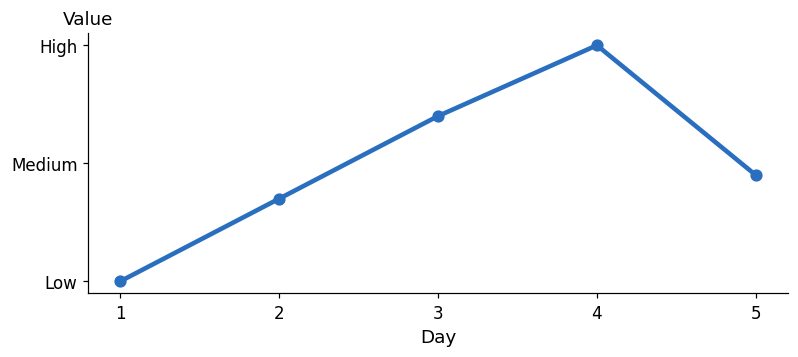

In [5]:
days = [1, 2, 3, 4, 5]
price = [0.0, 0.35, 0.7, 1.0, 0.45]
fig, ax = plt.subplots(figsize=(7.6, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.plot(days, price, color=BLUE, lw=3, marker="o", ms=7)
ax.set_xticks(days)
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels(["Low", "Medium", "High"])
ax.set_xlabel("Day", fontsize=12)
ax.tick_params(labelsize=11)
set_top_ylabel(ax, "Value", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### More Data for Older Companies

- The longer a company has been traded, the more data we have for it
- The <b style="color:#73000A;">blue</b> company has 9 days. The <b style="color:#73000A;">red</b> company has 5

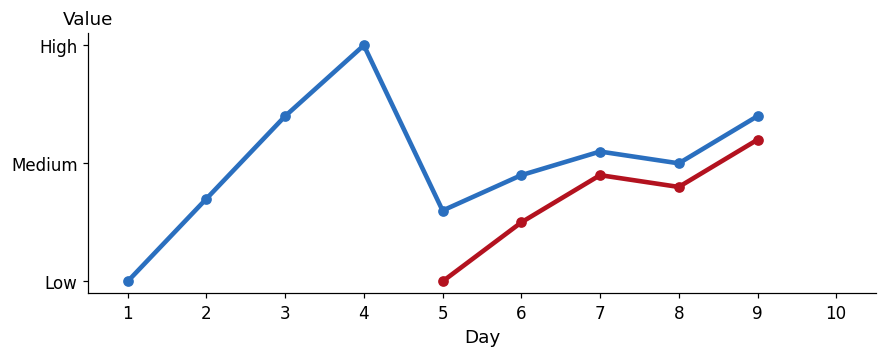

In [6]:
blue = [0.0, 0.35, 0.7, 1.0, 0.3, 0.45, 0.55, 0.5, 0.7]
red = [0.0, 0.25, 0.45, 0.4, 0.6]
fig, ax = plt.subplots(figsize=(8.4, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.plot(range(1, 10), blue, color=BLUE, lw=3, marker="o", ms=6)
ax.plot(range(5, 10), red, color=HOT, lw=3, marker="o", ms=6)
ax.set_xticks(range(1, 11))
ax.set_xlim(0.5, 10.5)
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels(["Low", "Medium", "High"])
ax.set_xlabel("Day", fontsize=12)
ax.tick_params(labelsize=11)
set_top_ylabel(ax, "Value", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### Predicting Day 10

- To predict the blue company on day 10, we might use all <b style="color:#73000A;">9</b> earlier days
- For the red company we only have the <b style="color:#73000A;">5</b> earlier days
- So the network has to be <b style="color:#73000A;">flexible</b> in how much sequential data it uses to make a prediction

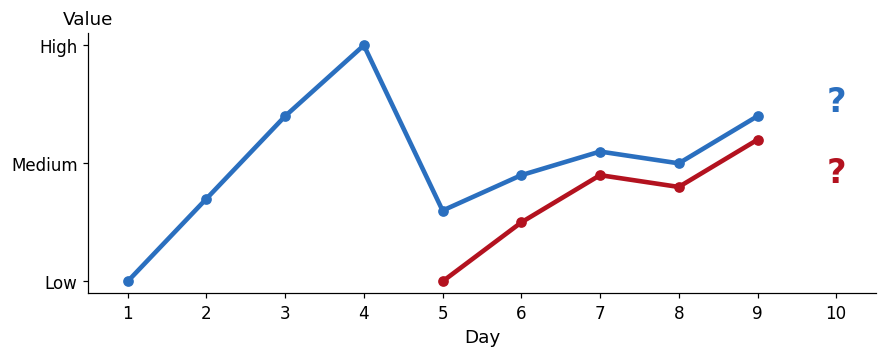

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.plot(range(1, 10), blue, color=BLUE, lw=3, marker="o", ms=6)
ax.plot(range(5, 10), red, color=HOT, lw=3, marker="o", ms=6)
ax.text(10, 0.72, "?", fontsize=22, color=BLUE, ha="center", weight="bold")
ax.text(10, 0.42, "?", fontsize=22, color=HOT, ha="center", weight="bold")
ax.set_xticks(range(1, 11))
ax.set_xlim(0.5, 10.5)
ax.set_yticks([0, 0.5, 1])
ax.set_yticklabels(["Low", "Medium", "High"])
ax.set_xlabel("Day", fontsize=12)
ax.tick_params(labelsize=11)
set_top_ylabel(ax, "Value", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### Every Network So Far Took a Fixed Number of Inputs

- Lecture 10's network made predictions from <b style="color:#73000A;">1</b> input value, no more and no less
- The iris network in lecture 12 took <b style="color:#73000A;">2</b> input values
- Lecture 13's CNN took a picture <b style="color:#73000A;">6 pixels by 6</b>, no bigger and no smaller
- Now we need one network that predicts from the blue company's <b style="color:#73000A;">9</b> values and from the red company's <b style="color:#73000A;">5</b>

### A Solution: A Recurrent Neural Network

- Just like the networks we've seen before, a <b style="color:#73000A;">Recurrent Neural Network (RNN)</b> has weights, biases, layers and activation functions
- The big difference is a <b style="color:#73000A;">feedback loop</b>



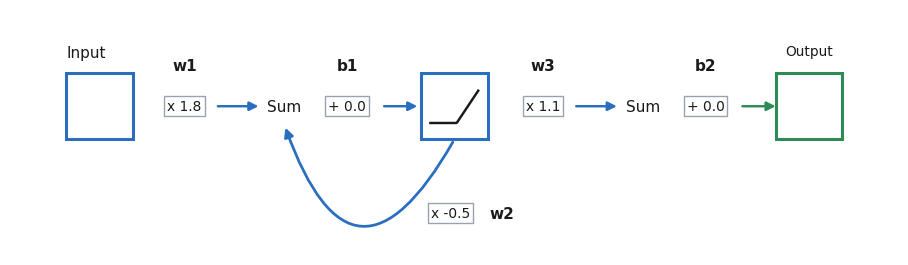

In [8]:
fig, ax = frame((10.4, 2.9), (-0.6, 11.4), (-2.0, 1.3))
rnn_rolled(ax)
for x, t in ((1.75, "w1"), (3.95, "b1"), (6.6, "w3"), (8.8, "b2")):
    note(ax, x, 0.55, t, fs=10, ha="center", weight="bold")
note(ax, 6.05, -1.45, "w2", fs=10, ha="center", weight="bold")
plt.show()

### The Feedback Loop Takes Sequential Values

- It may look like this network only takes a single input value
- The <b style="color:#73000A;">feedback loop</b> makes it possible to use sequential input values, like stock prices collected over time
- With 9 days of data, like the blue company, we use the feedback loop 9 times. With 5 days, 5 times

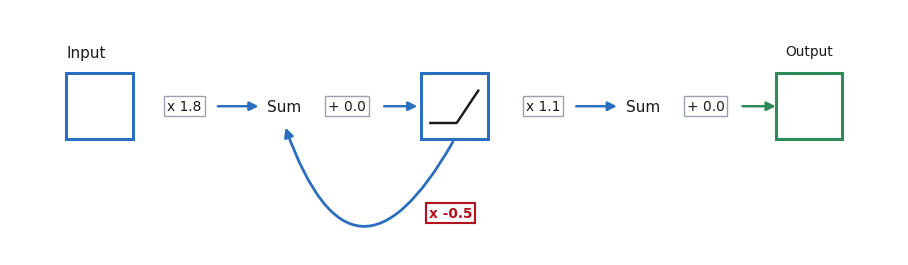

In [9]:
fig, ax = frame((10.4, 2.9), (-0.6, 11.4), (-2.0, 1.3))
rnn_rolled(ax, hot=("w2",))
plt.show()

## RNNs Step by Step

- The actual stock market is complicated
- In <b style="color:#73000A;">StatLand</b>, things are much simpler
- Prices are scaled so that <b style="color:#73000A;">Low = 0</b>, <b style="color:#73000A;">Medium = 0.5</b> and <b style="color:#73000A;">High = 1</b>

### Low Two Days in a Row

- If the price is low for two days in a row, then, more often than not, it stays low the next day

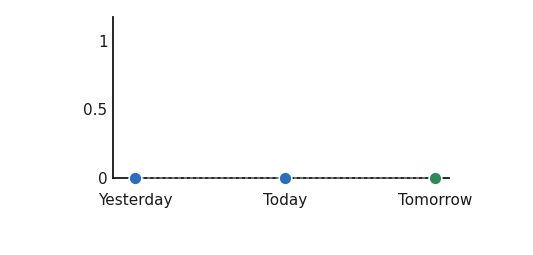

In [10]:
fig, ax = frame((6.0, 3.0), (-1.4, 5.6), (-0.9, 2.3))
price_panel(ax, 0.0, 0.0, [0, 0], w=4.6, h=2.2, tomorrow=0,
            labels=["Yesterday", "Today", "Tomorrow"], fs=10)
plt.show()

### Low, Then Medium

- If yesterday's price was low and today's is medium, then tomorrow's should be even higher

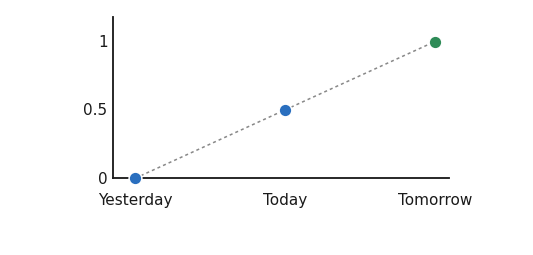

In [11]:
fig, ax = frame((6.0, 3.0), (-1.4, 5.6), (-0.9, 2.3))
price_panel(ax, 0.0, 0.0, [0, 0.5], w=4.6, h=2.2, tomorrow=1,
            labels=["Yesterday", "Today", "Tomorrow"], fs=10)
plt.show()

### High, Then Medium

- When the price decreases from high to medium, tomorrow's price will be even lower

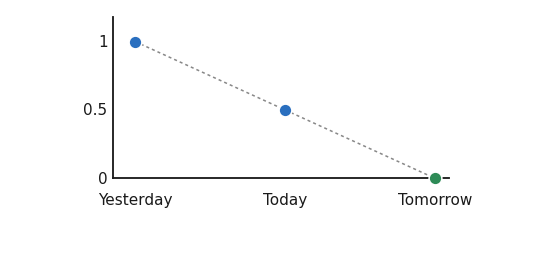

In [12]:
fig, ax = frame((6.0, 3.0), (-1.4, 5.6), (-0.9, 2.3))
price_panel(ax, 0.0, 0.0, [1, 0.5], w=4.6, h=2.2, tomorrow=0,
            labels=["Yesterday", "Today", "Tomorrow"], fs=10)
plt.show()

### High Two Days in a Row

- If the price stays high for two days in a row, it will be high tomorrow

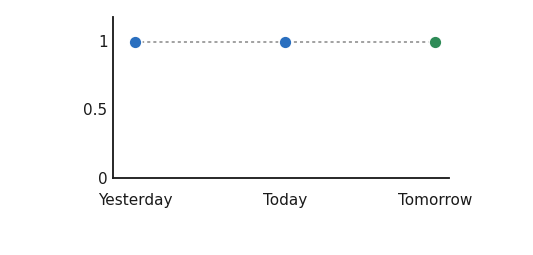

In [13]:
fig, ax = frame((6.0, 3.0), (-1.4, 5.6), (-0.9, 2.3))
price_panel(ax, 0.0, 0.0, [1, 1], w=4.6, h=2.2, tomorrow=1,
            labels=["Yesterday", "Today", "Tomorrow"], fs=10)
plt.show()

### The Four Trends

- Now we run yesterday's and today's values through the RNN and see if it predicts tomorrow's

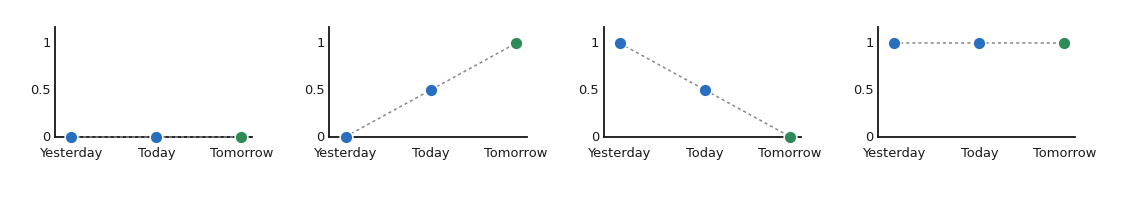

In [14]:
fig, ax = frame((13.0, 2.9), (-0.8, 19.4), (-0.9, 2.3))
for k, (y, t, tm) in enumerate([(0, 0, 0), (0, 0.5, 1), (1, 0.5, 0), (1, 1, 1)]):
    price_panel(ax, k * 5.0, 0.0, [y, t], w=3.6, h=2.0, tomorrow=tm,
                labels=["Yesterday", "Today", "Tomorrow"], fs=8.5)
plt.show()

### Yesterday's Value Into the Input

- Because of the feedback loop, we enter yesterday's and today's values <b style="color:#73000A;">one after the other</b>
- Start with yesterday's value, 0, and do the math like any other network
- $0 \times 1.8 + 0.0 = 0$, and ReLU gives $\max(0, 0) = 0$. Call this ReLU output <b style="color:#73000A;">$y_1$</b>

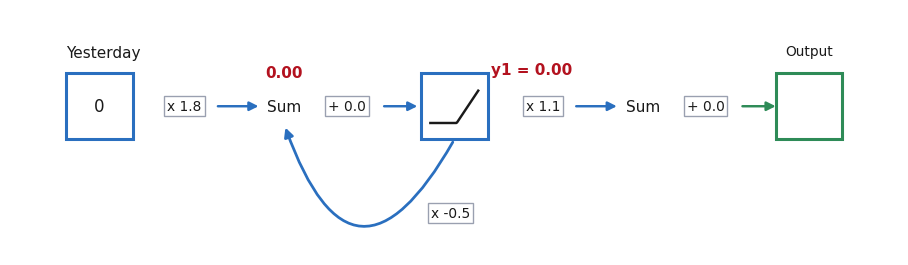

In [15]:
fig, ax = frame((10.4, 2.9), (-0.6, 11.4), (-2.0, 1.3))
rnn_rolled(ax, value=0, show_sum=0.0, show_act=0.0, label="Yesterday", sum_above=True, act_name="y1")
plt.show()

### $y_1$ Can Go Two Places

- First, toward the output: $y_1 \times 1.1 + 0.0 = 0 \times 1.1 + 0.0 = 0$
- That output is the <b style="color:#73000A;">predicted value for today</b>
- We already have the actual value for today, so we ignore this output. We want yesterday and today to predict <b style="color:#73000A;">tomorrow</b>

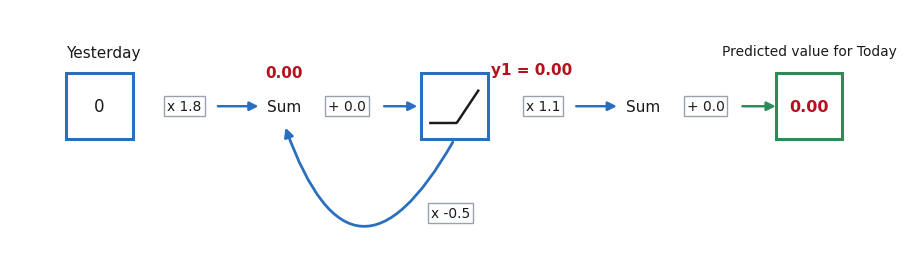

In [16]:
fig, ax = frame((10.4, 2.9), (-0.6, 11.4), (-2.0, 1.3))
rnn_rolled(ax, value=0, show_sum=0.0, show_act=0.0, out_value=0.0, label="Yesterday", sum_above=True, act_name="y1",
           out_label="Predicted value for Today")
plt.show()

### The Summation

- Second, $y_1$ goes around the feedback loop
- The sum adds $y_1 \times w_2$, which is based on yesterday's value, to today's value $\times\, w_1$:

$$(\text{Today} \times w_1) + (y_1 \times w_2)$$

- So the feedback loop lets <b style="color:#73000A;">both yesterday's and today's values</b> influence the prediction

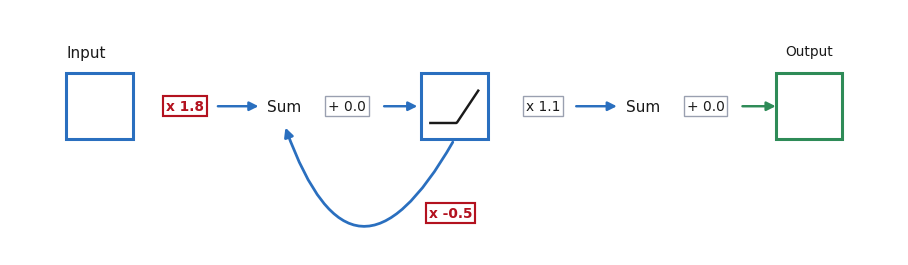

In [17]:
fig, ax = frame((10.4, 2.9), (-0.6, 11.4), (-2.0, 1.3))
rnn_rolled(ax, hot=("w1", "w2"))
plt.show()

### Unroll the Feedback Loop

- Keeping track of which value is in the loop and which is in the input is a headache
- Instead, <b style="color:#73000A;">unroll</b> the loop: make a copy of the network for each input value
- Point the feedback loop at the <b style="color:#73000A;">sum in the second copy</b>
- Two copies is the RNN <b style="color:#73000A;">unrolled once</b>: two inputs and two outputs

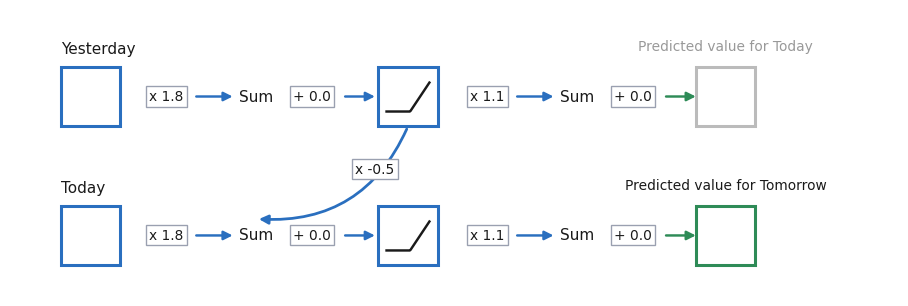

In [18]:
fig, ax = frame((10.4, 4.3), (-0.6, 12.8), (-3.0, 1.3))
rnn_unrolled(ax, [0, 0], values=False)
plt.show()

### Two Outputs, and We Want the Second

- The first output is the predicted value for today, which we ignore
- The second input is today's value. The connection from the first ReLU to the second sum lets both days influence the second output, the <b style="color:#73000A;">predicted value for tomorrow</b>

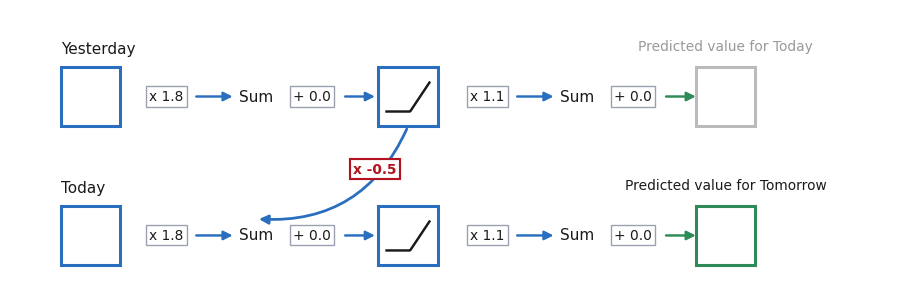

In [19]:
fig, ax = frame((10.4, 4.3), (-0.6, 12.8), (-3.0, 1.3))
rnn_unrolled(ax, [0, 0], values=False, hot=("w2",))
plt.show()

### Every Copy Shares the Same Weights and Biases

- Updating $w_1$ with backpropagation updates it in every copy, to the same value
- The same goes for every other weight and bias
- RNNs work on any sequential data, not only stock prices, for example spoken words for speech recognition

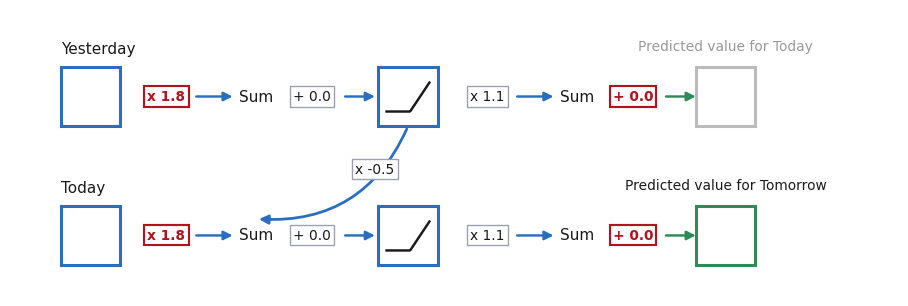

In [20]:
fig, ax = frame((10.4, 4.3), (-0.6, 12.8), (-3.0, 1.3))
rnn_unrolled(ax, [0, 0], values=False, hot=("w1", "b2"))
plt.show()

### Low, Low, by Hand

- Yesterday: $0 \times 1.8 + 0.0 = 0$. ReLU gives $y_1 = 0$. Around the loop: $0 \times -0.5 = 0$
- Today: $0 \times 1.8 + 0 + 0.0 = 0$. ReLU gives $y_2 = 0$
- Tomorrow: $y_2 \times 1.1 + 0.0 = 0 \times 1.1 + 0.0 =$ <b style="color:#73000A;">0</b>, low, which is correct

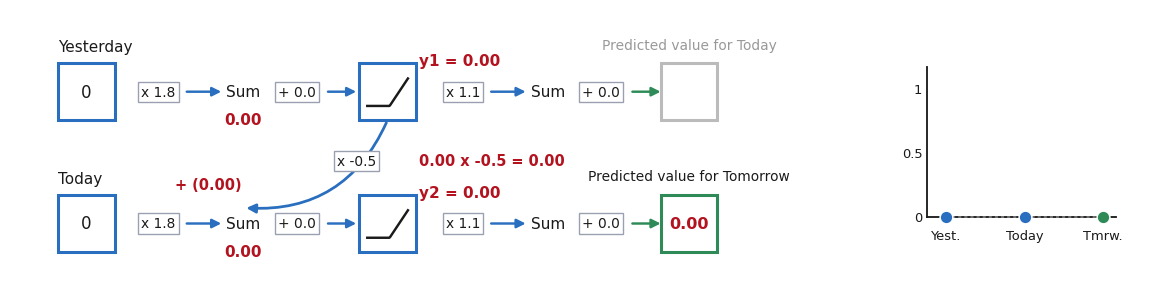

In [21]:
fig, ax = frame((13.4, 4.3), (-0.6, 17.6), (-3.0, 1.3))
run = rnn_unrolled(ax, [0, 0], show_math=True)
price_panel(ax, 14.0, -2.0, [0, 0], w=3.0, h=2.4, tomorrow=round(run[-1]["pred"]),
            labels=["Yest.", "Today", "Tmrw."], fs=8.5)
plt.show()

### Low, Then Medium, by Hand

- Yesterday: $0 \times 1.8 + 0.0 = 0$, so $y_1 = 0$ and $0 \times -0.5 = 0$
- Today: $0.5 \times 1.8 + 0 + 0.0 = 0.9$, so $y_2 = 0.9$
- Tomorrow: $0.9 \times 1.1 + 0.0 = 0.99$, about <b style="color:#73000A;">1</b>, high, which is correct

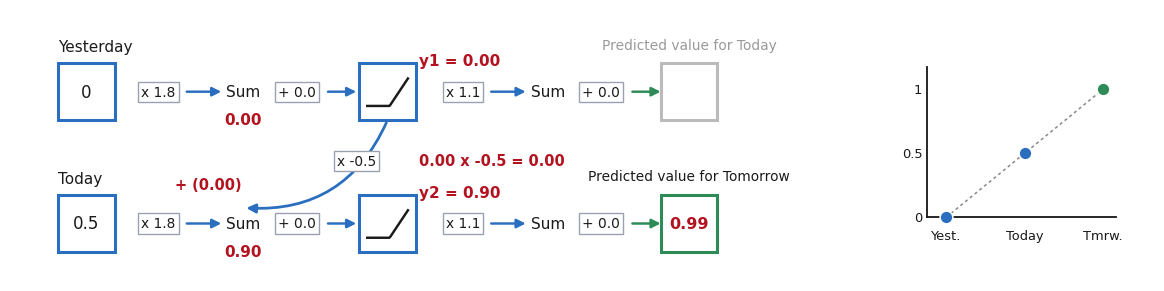

In [22]:
fig, ax = frame((13.4, 4.3), (-0.6, 17.6), (-3.0, 1.3))
run = rnn_unrolled(ax, [0, 0.5], show_math=True)
price_panel(ax, 14.0, -2.0, [0, 0.5], w=3.0, h=2.4, tomorrow=round(run[-1]["pred"]),
            labels=["Yest.", "Today", "Tmrw."], fs=8.5)
plt.show()

### High, Then Medium, by Hand

- Yesterday: $1 \times 1.8 + 0.0 = 1.8$, so $y_1 = 1.8$ and $1.8 \times -0.5 = -0.9$
- Today: $0.5 \times 1.8 + (-0.9) + 0.0 = 0$, so $y_2 = 0$
- Tomorrow: $0 \times 1.1 + 0.0 =$ <b style="color:#73000A;">0</b>, low, which is correct

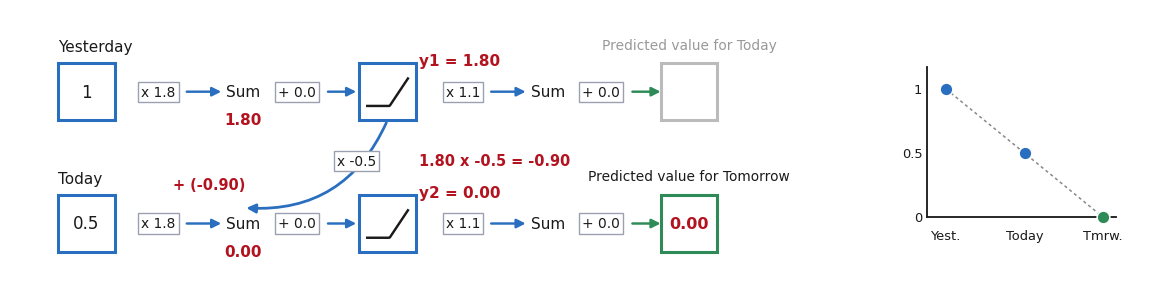

In [23]:
fig, ax = frame((13.4, 4.3), (-0.6, 17.6), (-3.0, 1.3))
run = rnn_unrolled(ax, [1, 0.5], show_math=True)
price_panel(ax, 14.0, -2.0, [1, 0.5], w=3.0, h=2.4, tomorrow=round(run[-1]["pred"]),
            labels=["Yest.", "Today", "Tmrw."], fs=8.5)
plt.show()

### High, High, by Hand

- Yesterday: $1 \times 1.8 + 0.0 = 1.8$, so $y_1 = 1.8$ and $1.8 \times -0.5 = -0.9$
- Today: $1 \times 1.8 + (-0.9) + 0.0 = 0.9$, so $y_2 = 0.9$
- Tomorrow: $0.9 \times 1.1 + 0.0 = 0.99$, about <b style="color:#73000A;">1</b>, high, which is correct

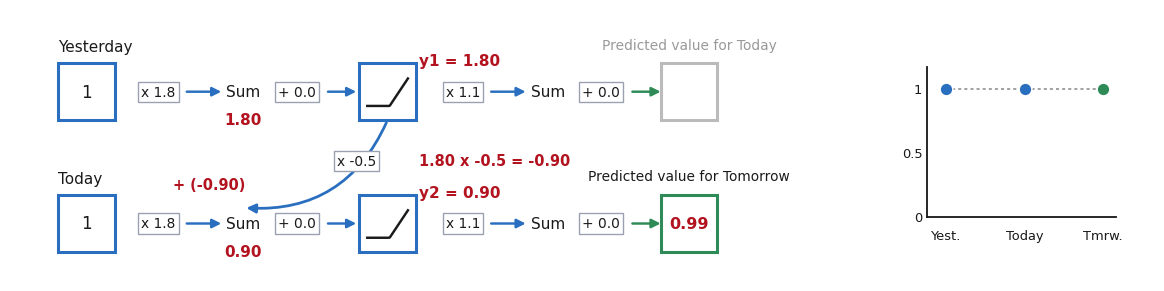

In [24]:
fig, ax = frame((13.4, 4.3), (-0.6, 17.6), (-3.0, 1.3))
run = rnn_unrolled(ax, [1, 1], show_math=True)
price_panel(ax, 14.0, -2.0, [1, 1], w=3.0, h=2.4, tomorrow=round(run[-1]["pred"]),
            labels=["Yest.", "Today", "Tmrw."], fs=8.5)
plt.show()

### What If We Have 3 Days?

- Keep unrolling until there is an input for each day: day before yesterday, yesterday and today
- Three copies is the RNN <b style="color:#73000A;">unrolled twice</b>
- Each time we unroll, we keep sharing the same weights and biases. The number we have to train with backpropagation <b style="color:#73000A;">stays the same</b>

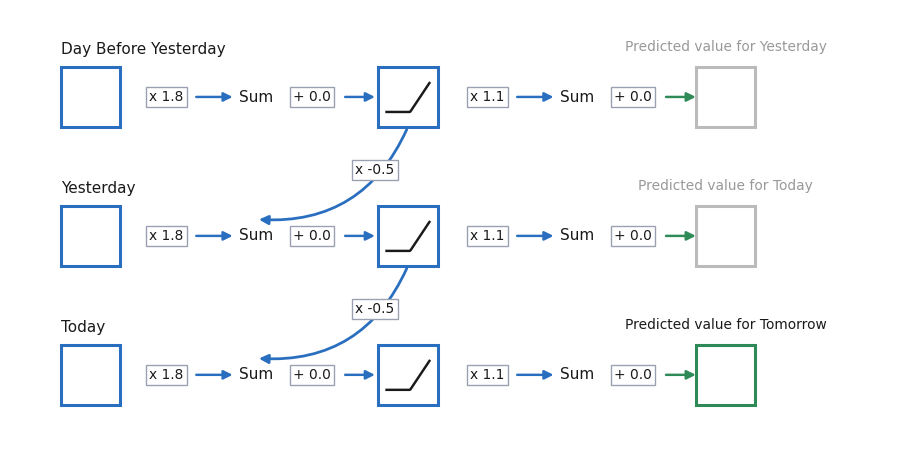

In [25]:
fig, ax = frame((10.4, 6.0), (-0.6, 12.8), (-5.2, 1.3))
rnn_unrolled(ax, [1, 0.5, 0.5], values=False)
plt.show()

### Oldest to Newest

- Plug the values in, always from oldest to newest: 1, then 0.5, then 0.5
- Day before yesterday: $1 \times 1.8 + 0.0 = 1.8$, so $y_1 = 1.8$ and $1.8 \times -0.5 = -0.9$
- Yesterday: $0.5 \times 1.8 + (-0.9) + 0.0 = 0$, so $y_2 = 0$ and $0 \times -0.5 = 0$
- Today: $0.5 \times 1.8 + 0 + 0.0 = 0.9$, so $y_3 = 0.9$
- Tomorrow: $0.9 \times 1.1 + 0.0 = 0.99$, about <b style="color:#73000A;">1</b>

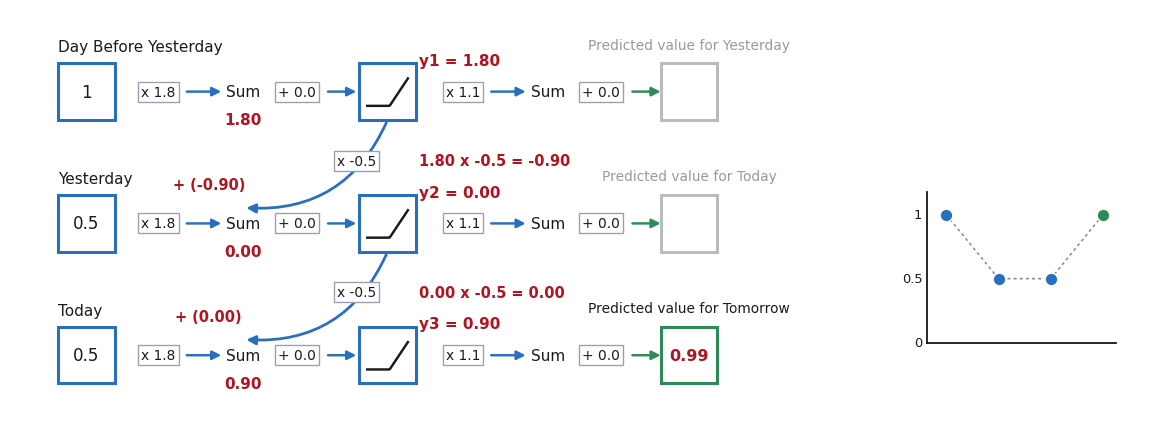

In [26]:
fig, ax = frame((13.4, 6.0), (-0.6, 17.6), (-5.2, 1.3))
run = rnn_unrolled(ax, [1, 0.5, 0.5], show_math=True)
price_panel(ax, 14.0, -4.0, [1, 0.5, 0.5], w=3.0, h=2.4, tomorrow=1,
            labels=["", "", "", ""], fs=8.5)
plt.show()

### Shared Across Every Input

- This unrolled network has 3 inputs, and $w_1$ is the same for all 3. So is $b_1$
- All the other weights and biases are shared too
- No matter how many times we unroll, we <b style="color:#73000A;">never increase</b> the number of weights and biases we have to train

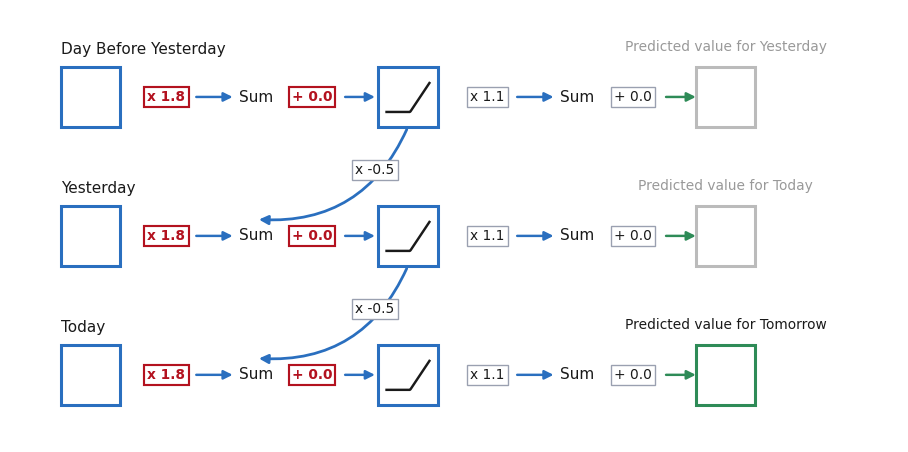

In [27]:
fig, ax = frame((10.4, 6.0), (-0.6, 12.8), (-5.2, 1.3))
rnn_unrolled(ax, [1, 0.5, 0.5], values=False, hot=("w1", "b1"))
plt.show()

### In Summary

- Basic RNNs expand, by unrolling, to handle any size dataset without increasing the number of weights and biases we need to train
- Next: backpropagation through an RNN, and the problems it creates for the basic version

## Backpropagation Through an RNN

- Start with the simplest RNN ever: <b style="color:#73000A;">2 weights</b>, $W_1$ and $W_2$
- No activation function and no biases
- As in lecture 11, measure the difference between Observed and Predicted with the sum of the squared residuals:

$$\text{SSR} = \sum_{i=1}^{n} (\text{Observed}_i - \text{Predicted}_i)^2$$

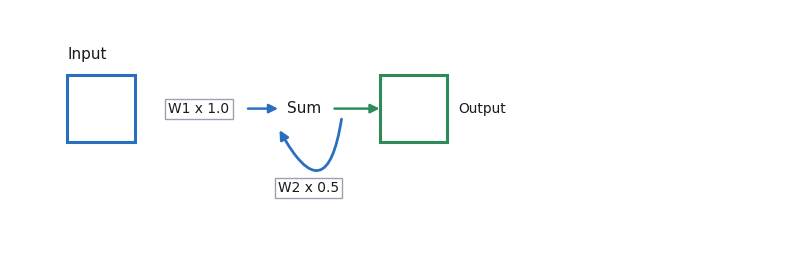

In [28]:
fig, ax = frame((9.0, 3.0), (-0.6, 9.6), (-1.8, 1.3))
bp_rolled(ax)
plt.show()

### Just Today's Value

- To keep it simple at the start, use only <b style="color:#73000A;">today's</b> value to predict tomorrow's
- With a single input value we can ignore the feedback loop
- The prediction is today's value times $W_1$: $\;\text{Predicted} = \text{Today} \times W_1$

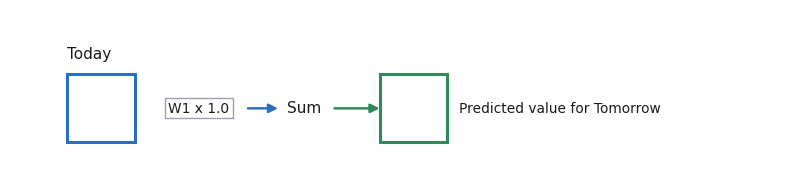

In [29]:
fig, ax = frame((9.0, 1.9), (-0.6, 9.6), (-0.7, 1.3))
bp_rolled(ax, label="Today", out_label="Predicted value for Tomorrow", loop=False)
plt.show()

### The Chain Rule

- The SSR is linked to $W_1$ by the Predicted values, so the chain rule says

$$\frac{d\,\text{SSR}}{d\,W_1} = \frac{d\,\text{SSR}}{d\,\text{Predicted}} \times \frac{d\,\text{Predicted}}{d\,W_1}$$

- First piece, one squared residual at a time. The outside is a square, the inside is Observed minus Predicted:

$$\frac{d}{d\,\text{Predicted}}(\text{Observed} - \text{Predicted})^2 = 2(\text{Observed} - \text{Predicted}) \times (-1) = -2(\text{Observed} - \text{Predicted})$$

- Add them up: $\;\dfrac{d\,\text{SSR}}{d\,\text{Predicted}} = \sum -2(\text{Observed}_i - \text{Predicted}_i)$

### The Derivative With One Input

- Second piece. Predicted is Today times $W_1$, and Today does not depend on $W_1$:

$$\frac{d\,\text{Predicted}}{d\,W_1} = \frac{d}{d\,W_1}(\text{Today} \times W_1) = \text{Today}$$

- Multiply the two pieces:

$$\frac{d\,\text{SSR}}{d\,W_1} = \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \text{Today}$$

### Unrolled Once: Yesterday and Today

- With yesterday's and today's values, unroll the RNN to allow for two inputs
- Yesterday's value goes through $W_1$, then around the loop through $W_2$. Today's value goes through $W_1$:

$$\text{Predicted} = (\text{Yesterday} \times W_1 \times W_2) + (\text{Today} \times W_1)$$

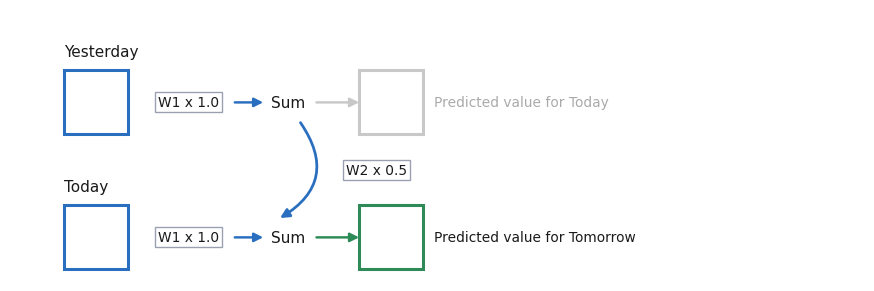

In [30]:
fig, ax = frame((10.0, 3.6), (-0.6, 11.4), (-2.5, 1.3))
bp_unrolled(ax, ["Yesterday", "Today"], out_labels=["Predicted value for Today"])
plt.show()

### The Derivative With Two Inputs

- Take the derivative one term at a time. Yesterday and $W_2$ are constants as far as $W_1$ is concerned:

$$\frac{d\,\text{Predicted}}{d\,W_1} = \frac{d}{d\,W_1}\big[(\text{Yesterday} \times W_1 \times W_2) + (\text{Today} \times W_1)\big] = (\text{Yesterday} \times W_2) + \text{Today}$$

- Multiply by the first piece, which has not changed:

$$\frac{d\,\text{SSR}}{d\,W_1} = \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \big[(\text{Yesterday} \times W_2) + \text{Today}\big]$$

### Unrolled Twice: Three Days

- Multiply the day before yesterday's value by $W_1$ and $W_2$, add yesterday's value times $W_1$, multiply that sum by $W_2$, then add today's value times $W_1$:

$$\text{Predicted} = \big\{[(\text{DBY} \times W_1 \times W_2) + (\text{Yesterday} \times W_1)] \times W_2\big\} + (\text{Today} \times W_1)$$

- Multiply the square brackets by that last $W_2$:

$$\text{Predicted} = (\text{DBY} \times W_1 \times W_2^2) + (\text{Yesterday} \times W_1 \times W_2) + (\text{Today} \times W_1)$$

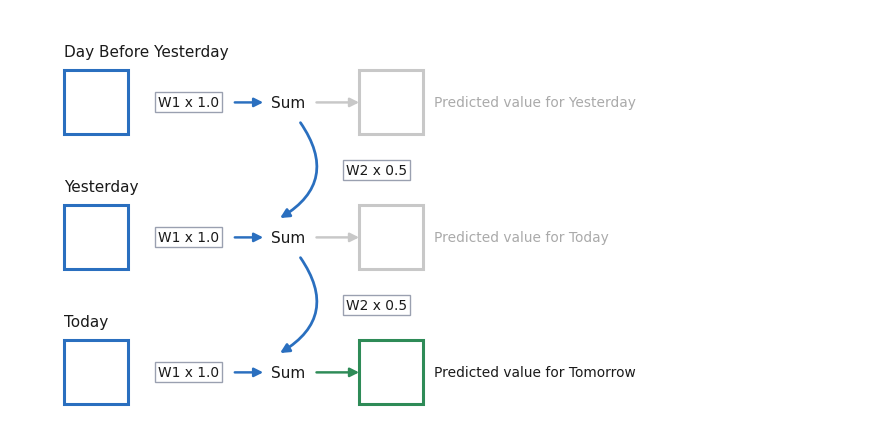

In [31]:
fig, ax = frame((10.0, 5.0), (-0.6, 11.4), (-4.4, 1.3))
bp_unrolled(ax, ["Day Before Yesterday", "Yesterday", "Today"],
            out_labels=["Predicted value for Yesterday", "Predicted value for Today"])
plt.show()

### The Derivative With Three Inputs

$$\frac{d\,\text{Predicted}}{d\,W_1} = (\text{DBY} \times W_2^2) + (\text{Yesterday} \times W_2) + \text{Today}$$

$$\frac{d\,\text{SSR}}{d\,W_1} = \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \big[(\text{DBY} \times W_2^2) + (\text{Yesterday} \times W_2) + \text{Today}\big]$$

- When backpropagation is applied to RNNs, it's called <b style="color:#73000A;">Backpropagation Through Time</b>

### The Power on $W_2$ Counts the Unrolls

- We unrolled twice to include the day before yesterday, and its value is multiplied by <b style="color:#73000A;">$W_2^2$</b>. It passes through $W_2$ twice on its way to the prediction
- We unrolled once to include yesterday, and its value is multiplied by $W_2 = W_2^1$
- We didn't unroll to include today, and its value is multiplied by $W_2^0 = 1$
- Now let's see how this pattern leads to trouble

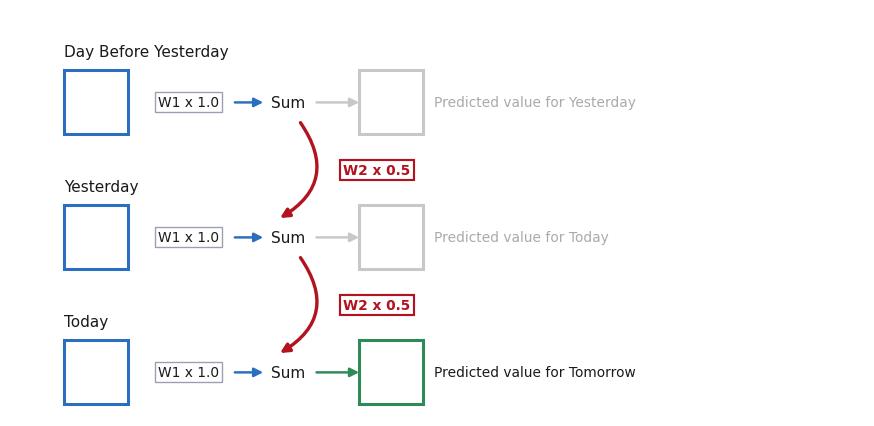

In [32]:
fig, ax = frame((10.0, 5.0), (-0.6, 11.4), (-4.4, 1.3))
bp_unrolled(ax, ["Day Before Yesterday", "Yesterday", "Today"], hot_w2=(0, 1),
            out_labels=["Predicted value for Yesterday", "Predicted value for Today"])
plt.show()

## The Vanishing/Exploding Gradient Problem

- Basic RNNs are not used very often. The more we unroll, the <b style="color:#73000A;">harder it is to train</b>
- Input values get multiplied by the same weight a bunch of times, so older data points end up with too little or too much influence on training
- <b style="color:#73000A;">Gradient</b> here means the derivatives we calculate for gradient descent

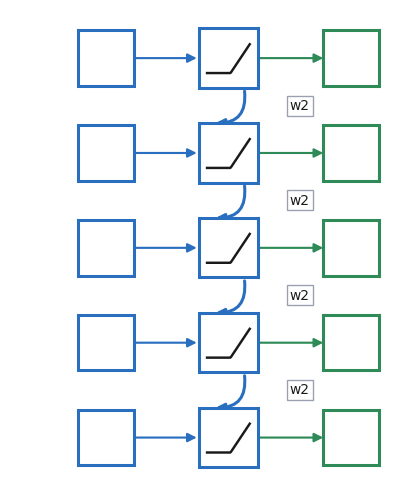

In [33]:
fig, ax = frame((5.6, 5.6), (-0.6, 4.4), (-5.4, 0.6))
chain5(ax)
plt.show()

### The Weight Along the Squiggle

- The problem is the weight on the squiggle, $w_2$, which we copy each time we unroll
- If $w_2$ is between $-1$ and $1$, parts of the gradient <b style="color:#73000A;">vanish</b>
- If $w_2$ is less than $-1$ or greater than $1$, they <b style="color:#73000A;">explode</b>
- To make it easier to see, ignore the other weights and biases and focus on $w_2$

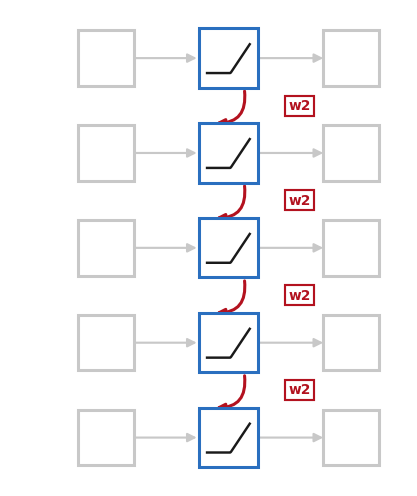

In [34]:
fig, ax = frame((5.6, 5.6), (-0.6, 4.4), (-5.4, 0.6))
chain5(ax, hot=("all",), fade_ends=True)
plt.show()

### Reminder: Gradients and Gradient Descent

- Backpropagation finds the derivatives, or <b style="color:#73000A;">gradients</b>, for each parameter
- Gradient descent plugs them in to find the parameter values that minimize a loss function, like the sum of the squared residuals
- Relatively small steps walk down to the lowest point

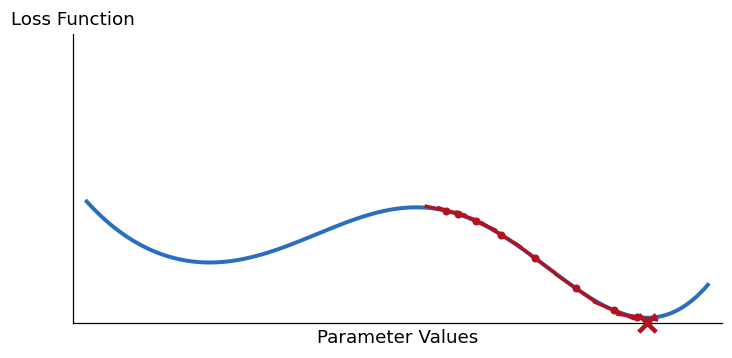

In [35]:
fig, ax = plt.subplots(figsize=(7.0, 3.6), dpi=110)
fig.patch.set_facecolor("white")
loss_plot(ax, "small")
fig.tight_layout()
plt.show()

### Exploding: Set $w_2$ to 2

- The gradient explodes when $w_2$ is larger than 1, so set $w_2 = 2$
- The first input is multiplied by 2 on the first squiggle, and again on the next, and the next, and the last:

$$\text{Input}_1 \times 2 \times 2 \times 2 \times 2 = \text{Input}_1 \times 2^4 = \text{Input}_1 \times w_2^{\text{Num. Unroll}}$$

- We unrolled 4 times, and $2^4 = 16$: the first input is <b style="color:#73000A;">amplified 16 times</b> before it reaches the last copy

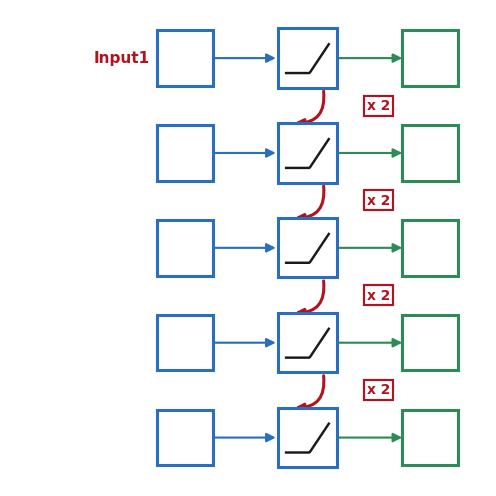

In [36]:
fig, ax = frame((5.6, 5.6), (-1.6, 4.4), (-5.4, 0.6))
chain5(ax, w2="x 2", hot=("all",), input1=True)
plt.show()

### 21 Days: Unrolled 20 Times

- With 21 days of data, the oldest point, $D_{-20}$, is multiplied by $2^{20}$:

$$\frac{d\,\text{SSR}}{d\,W_1} = \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \big[(D_{-20} \times 2^{20}) + \dots + D_0\big]$$

$$= \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \big[(D_{-20} \times 1{,}048{,}576) + \dots + D_0\big]$$

- $D_{-20}$ <b style="color:#73000A;">completely dwarfs</b> $D_0$, which isn't scaled at all. The part of the gradient for $D_{-20}$ explodes

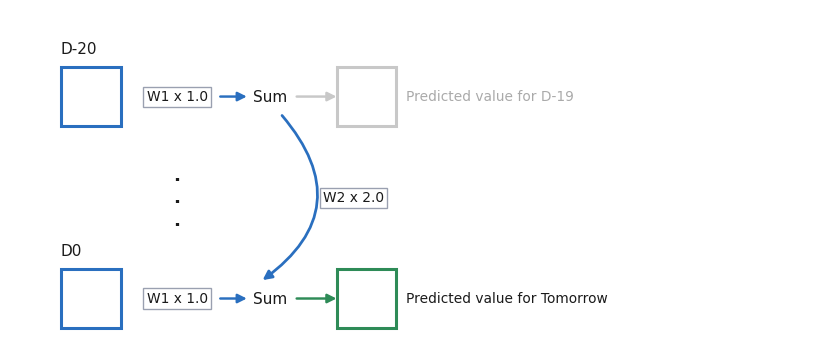

In [37]:
fig, ax = frame((10.0, 4.0), (-0.6, 11.4), (-3.8, 1.3))
bp_unrolled(ax, ["D-20", "D0"], w2=2.0, ellipsis_after=0,
            out_labels=["Predicted value for D-19"])
plt.show()

### 50 Days: A Huge Number

- 50 days of stock prices really isn't that much data
- Unroll about 50 times and the first input is multiplied by $2^{50} = 1{,}125{,}899{,}906{,}842{,}624$, <b style="color:#73000A;">a huge number</b>
- That huge number finds its way into some of the gradients, which makes it hard to take small steps toward the best weights and biases

### Huge Steps Bounce Around

- To find the parameter values with the lowest loss, we usually want relatively <b style="color:#73000A;">small steps</b>
- When the gradient contains a huge number, the steps are relatively large
- Instead of finding the optimal value, we <b style="color:#73000A;">bounce around</b> a lot

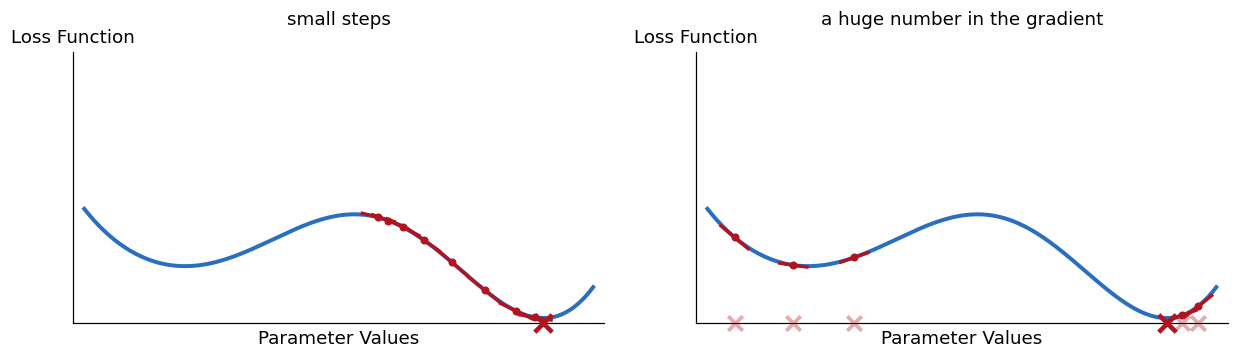

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.6), dpi=110)
fig.patch.set_facecolor("white")
loss_plot(axes[0], "small")
loss_plot(axes[1], "large")
axes[0].set_title("small steps", fontsize=12, pad=18)
axes[1].set_title("a huge number in the gradient", fontsize=12, pad=18)
fig.tight_layout()
plt.show()

### Vanishing: Set $w_2$ to 0.5

- One way to stop the exploding gradient is to keep $w_2$ <b style="color:#73000A;">below 1</b>
- That causes the vanishing gradient problem. Set $w_2 = 0.5$, and with 4 days the oldest, $D_{-3}$, is unrolled 3 times:

$$\big[(D_{-3} \times 0.5^3) + (D_{-2} \times 0.5^2) + (D_{-1} \times 0.5^1) + D_0\big] = \big[(D_{-3} \times 0.125) + (D_{-2} \times 0.25) + (D_{-1} \times 0.5) + D_0\big]$$

- $D_{-3}$ contributes a lot less to the derivative than $D_0$, which doesn't shrink at all

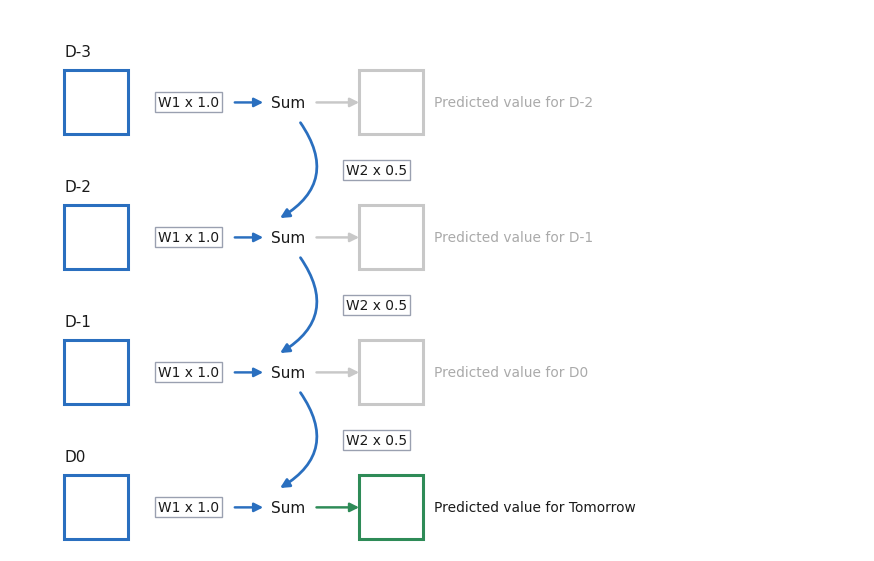

In [39]:
fig, ax = frame((10.0, 6.6), (-0.6, 11.4), (-6.3, 1.3))
bp_unrolled(ax, ["D-3", "D-2", "D-1", "D0"], w2=0.5,
            out_labels=["Predicted value for D-2", "Predicted value for D-1", "Predicted value for D0"])
plt.show()

### 11 Days and 21 Days

- With 11 days, unroll 10 times: $0.5^{10} = 0.00098$, about <b style="color:#73000A;">0.001</b>
- With 21 days, unroll 20 times: $0.5^{20} = 0.00000095$, about <b style="color:#73000A;">0.000001</b>

$$\frac{d\,\text{SSR}}{d\,W_1} = \sum -2(\text{Observed}_i - \text{Predicted}_i) \times \big[(D_{-20} \times 0.000001) + \dots + D_0\big]$$

- $D_{-20}$ is basically reduced to 0 and plays no significant role in training. The part of the gradient for $D_{-20}$ <b style="color:#73000A;">vanishes</b>

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 10px; border-radius:8px; font-weight:700; font-size:.8em;">Errata</span> &nbsp;Older printings show 0.000000001 here. The published errata correct it to 0.000001.

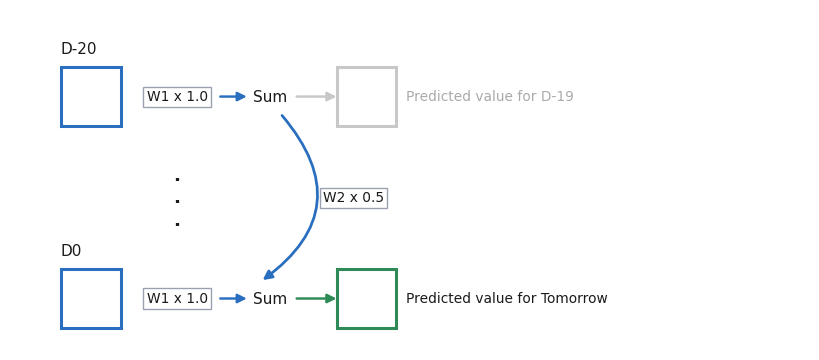

In [40]:
fig, ax = frame((10.0, 4.0), (-0.6, 11.4), (-3.8, 1.3))
bp_unrolled(ax, ["D-20", "D0"], w2=0.5, ellipsis_after=0,
            out_labels=["Predicted value for D-19"])
plt.show()

### 50 Days: Super Close to 0

- With 50 sequential values, the first input is multiplied by about $0.5^{50} = 0.00000000000000089$, a number <b style="color:#73000A;">super close to 0</b>
- Now the steps are <b style="color:#73000A;">too small</b> instead of too large
- We hit the maximum number of steps we are allowed to take before we find the optimal value

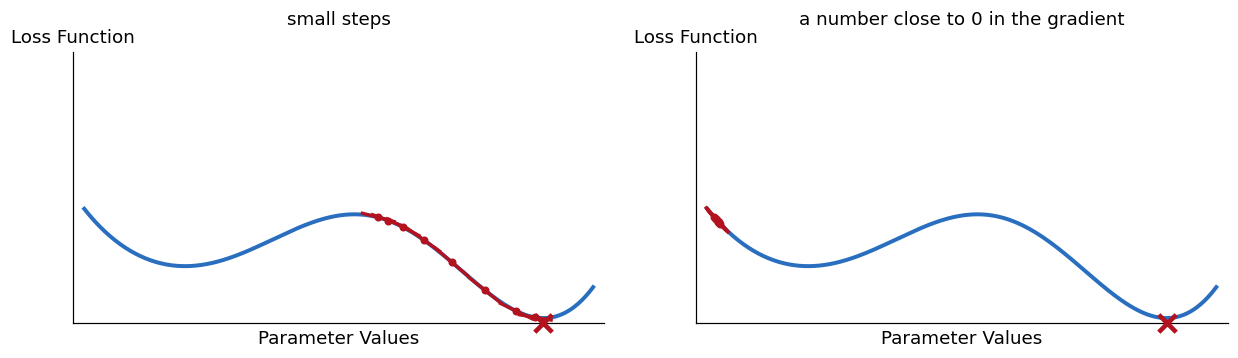

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 3.6), dpi=110)
fig.patch.set_facecolor("white")
loss_plot(axes[0], "small")
loss_plot(axes[1], "tiny")
axes[0].set_title("small steps", fontsize=12, pad=18)
axes[1].set_title("a number close to 0 in the gradient", fontsize=12, pad=18)
fig.tight_layout()
plt.show()

### What Repeated Multiplication Does

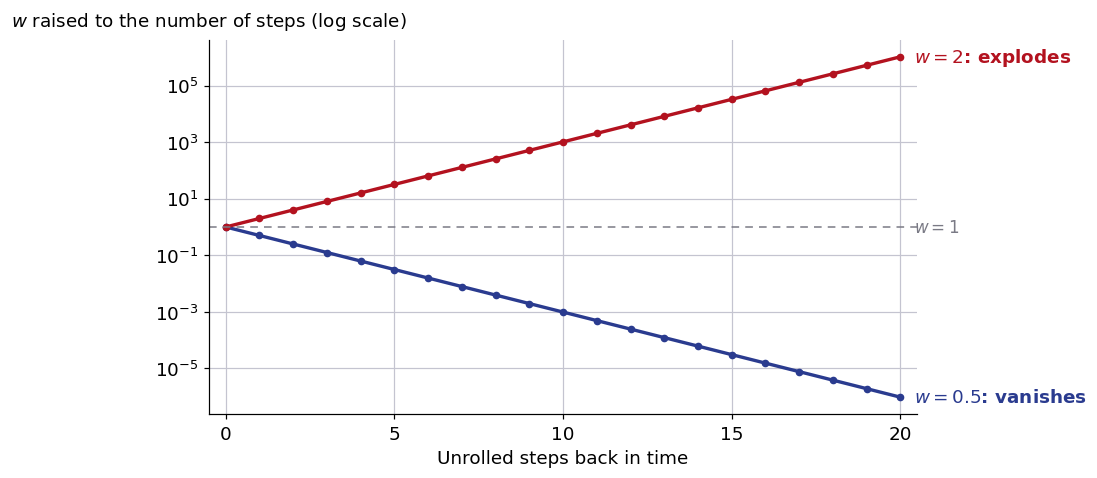

In [42]:
steps = np.arange(0, 21)
fig, ax = plt.subplots(figsize=(9.2, 4.6), dpi=110)
fig.patch.set_facecolor("white"); ax.set_facecolor("white")
ax.grid(True, color="#C4C4D0", lw=0.8, zorder=0); ax.set_axisbelow(True)
ax.semilogy(steps, 0.5 ** steps, "o-", color=chh.MADRID, lw=2.2, ms=4)
ax.semilogy(steps, 2.0 ** steps, "o-", color=chh.FITLINE, lw=2.2, ms=4)
ax.axhline(1.0, color="#7A7A85", ls=(0, (5, 4)), lw=1)
# label each line at its right end instead of a legend box over the lines
ax.text(20.4, 2.0 ** 20, "$w = 2$: explodes", va="center", fontsize=12, color=chh.FITLINE, weight="bold")
ax.text(20.4, 0.5 ** 20, "$w = 0.5$: vanishes", va="center", fontsize=12, color=chh.MADRID, weight="bold")
ax.text(20.4, 1.0, "$w = 1$", va="center", fontsize=11, color="#7A7A85")
ax.set_xlim(-0.5, 20.5)
ax.set_xticks([0, 5, 10, 15, 20])
ax.set_xlabel("Unrolled steps back in time", fontsize=12)
ax.tick_params(labelsize=12)
set_top_ylabel(ax, "$w$ raised to the number of steps (log scale)", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.subplots_adjust(left=0.10, right=0.80, top=0.88, bottom=0.14)
plt.show()

### The Two Problems in Summary

- When $w_2$ is between $-1$ and $1$, it doesn't take much before older data points become <b style="color:#73000A;">insignificant</b>: 21 days back counts 0.000001
- When $w_2$ is less than $-1$ or greater than $1$, it doesn't take much before older data points <b style="color:#73000A;">completely overwhelm</b> the newer ones: 1,048,576
- It doesn't take much to reduce these effects. One way is <b style="color:#73000A;">Long Short-Term Memory</b>

## Long Short-Term Memory

- <b style="color:#73000A;">Long Short-Term Memory (LSTM)</b> is a type of recurrent neural network designed to avoid the vanishing/exploding gradient problem
- A basic RNN uses the same feedback loop for events long ago and events yesterday
- An LSTM uses <b style="color:#73000A;">two separate paths</b> to make predictions about tomorrow: one for <b style="color:#73000A;">long-term memories</b> and one for <b style="color:#73000A;">short-term memories</b>

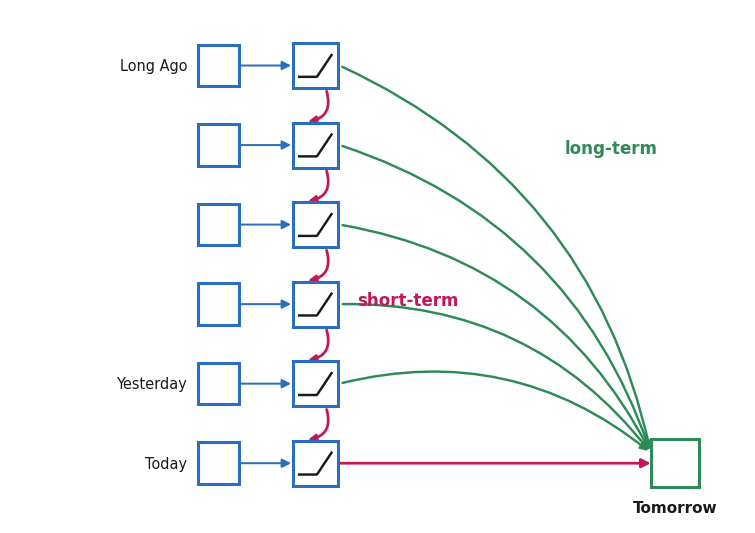

In [43]:
fig, ax = frame((8.6, 6.4), (-2.4, 8.2), (-6.6, 0.8))
two_paths(ax)
note(ax, 5.6, -1.2, "long-term", fs=11, color=GREEN, weight="bold")
note(ax, 2.6, -3.4, "short-term", fs=11, color=PINK, weight="bold")
plt.show()

### Made From Relatively Simple Parts

- Compared to a basic RNN, which unrolls from a simple unit, the LSTM unit looks complicated
- Like all neural networks, it is made from <b style="color:#73000A;">relatively simple parts</b>: weights, biases, sums, and activation functions
- We'll go through it one step at a time

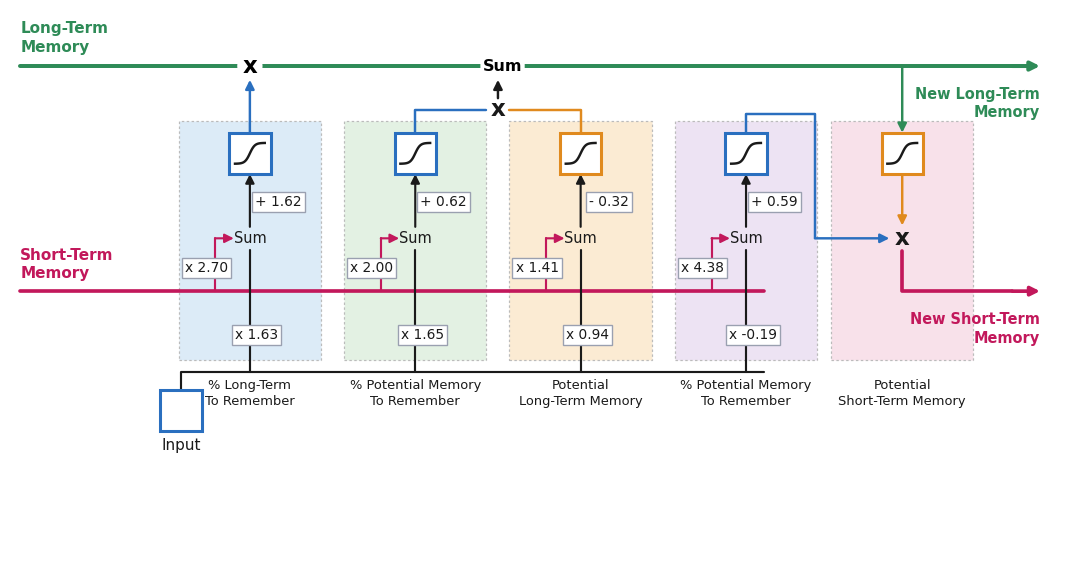

In [44]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, labels=True)
plt.show()

### The Sigmoid Activation Function

$$f(x) = \frac{e^x}{e^x + 1}$$

- Takes any x-axis coordinate and turns it into a y-axis coordinate <b style="color:#73000A;">between 0 and 1</b>
- $f(5) = \dfrac{e^5}{e^5 + 1} = \dfrac{148.4}{149.4} = 0.99$
- $f(10) = 0.99995$ and $f(-5) = 0.01$

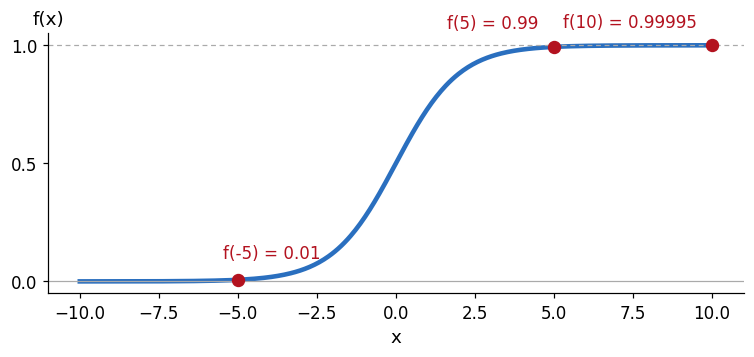

In [45]:
x = np.linspace(-10, 10, 400)
fig, ax = plt.subplots(figsize=(7.2, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.plot(x, np.exp(x) / (np.exp(x) + 1), color=BLUE, lw=3)
for v in (-5, 5, 10):
    fv = np.exp(v) / (np.exp(v) + 1)
    ax.scatter([v], [fv], s=60, color=HOT, zorder=5)
    ax.annotate("f(%d) = %s" % (v, "%.5f" % fv if v == 10 else "%.2f" % fv), (v, fv),
                textcoords="offset points", xytext=(-10, 12 if v != -5 else 14),
                ha="right" if v > 0 else "left", fontsize=11, color=HOT)
ax.axhline(0, color="#AAAAAA", lw=0.8); ax.axhline(1, color="#AAAAAA", lw=0.8, ls=(0, (4, 3)))
ax.set_yticks([0, 0.5, 1]); ax.tick_params(labelsize=11)
ax.set_xlabel("x", fontsize=12)
set_top_ylabel(ax, "f(x)", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### The Tanh Activation Function

$$f(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$$

- <b style="color:#73000A;">Tanh</b>, short for hyperbolic tangent, turns any x-axis coordinate into a y-axis coordinate <b style="color:#73000A;">between $-1$ and $1$</b>
- $f(2) = \dfrac{7.39 - 0.14}{7.39 + 0.14} = 0.96$, and $f(-2) = -0.96$
- $f(-5) = -1$

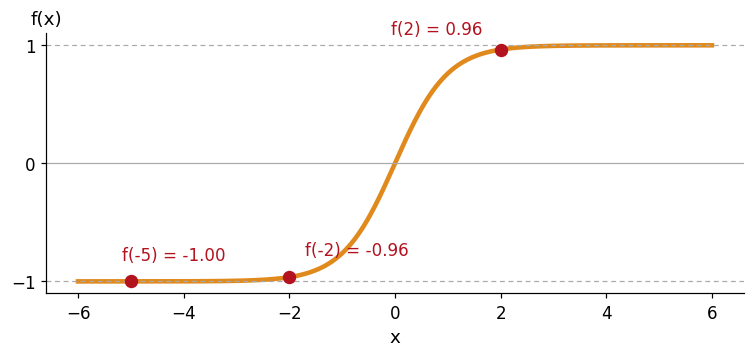

In [46]:
x = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(figsize=(7.2, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.plot(x, np.tanh(x), color=ORANGE, lw=3)
for v, off in ((2, (-12, 10)), (-2, (10, 14)), (-5, (-6, 14))):
    fv = np.tanh(v)
    ax.scatter([v], [fv], s=60, color=HOT, zorder=5)
    ax.annotate("f(%d) = %.2f" % (v, fv), (v, fv), textcoords="offset points",
                xytext=off, ha="right" if v > 0 else "left", fontsize=11, color=HOT)
ax.axhline(0, color="#AAAAAA", lw=0.8)
for h in (-1, 1):
    ax.axhline(h, color="#AAAAAA", lw=0.8, ls=(0, (4, 3)))
ax.set_yticks([-1, 0, 1]); ax.tick_params(labelsize=11)
ax.set_xlabel("x", fontsize=12)
set_top_ylabel(ax, "f(x)", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### The Long-Term Memory

- The <b style="color:#73000A;">green line</b> across the top is the <b style="color:#73000A;">Long-Term Memory</b>
- It can be changed by this multiplication and then by this addition
- But <b style="color:#73000A;">no weights or biases</b> modify it directly
- So long-term memories can flow through a series of unrolled units without making the gradient explode or vanish

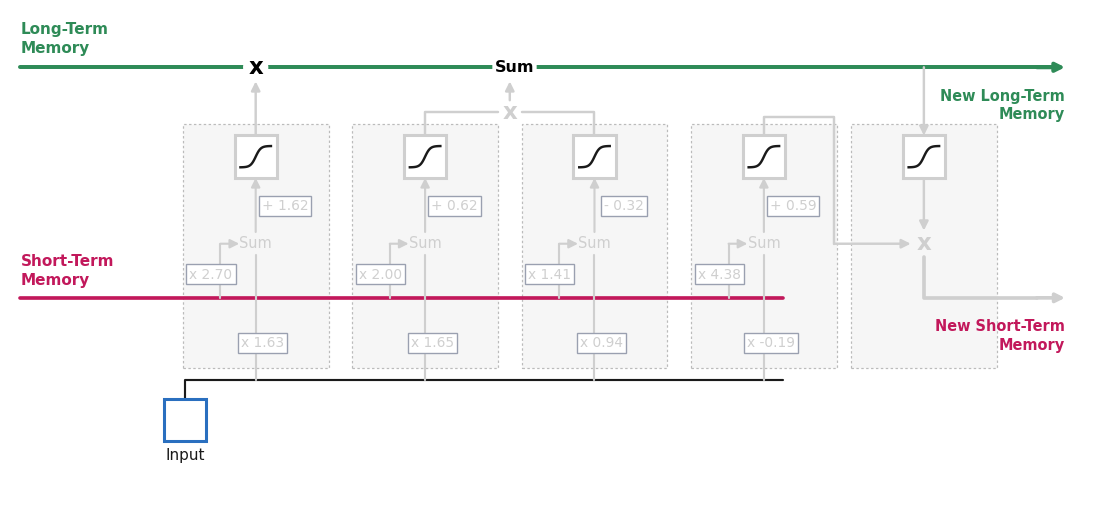

In [47]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, focus=())
plt.show()

### The Short-Term Memory

- The <b style="color:#73000A;">pink line</b> is the <b style="color:#73000A;">Short-Term Memory</b>
- Short-term memories are <b style="color:#73000A;">directly connected to weights</b> that can modify them: 2.70, 2.00, 1.41 and 4.38
- The input has its own weights: 1.63, 1.65, 0.94 and $-0.19$

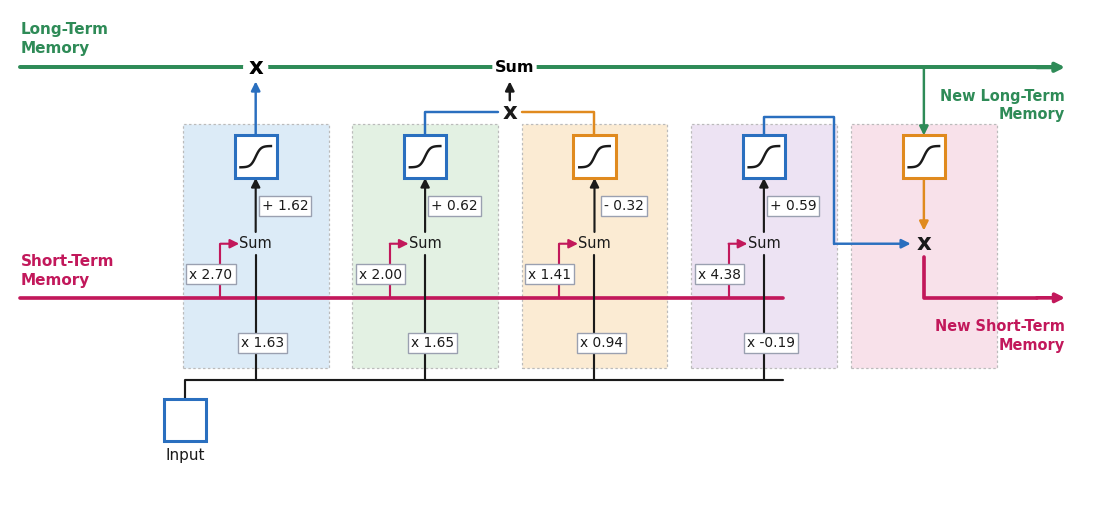

In [48]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax)
plt.show()

### Run Some Numbers

- To see how the long- and short-term memories interact, run numbers through the unit
- Previous Long-Term Memory: <b style="color:#73000A;">2</b>
- Previous Short-Term Memory: <b style="color:#73000A;">1</b>
- Input: <b style="color:#73000A;">1</b>

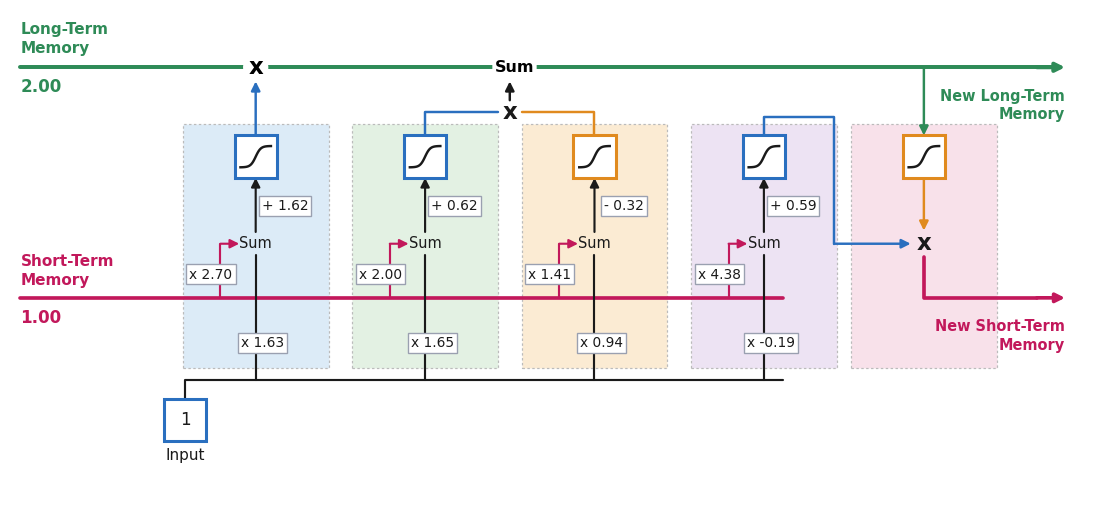

In [49]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1)
plt.show()

### Stage 1: Into the Sigmoid

- Short-Term Memory times its weight, plus Input times its weight, plus the bias:

$$(1 \times 2.70) + (1 \times 1.63) + 1.62 = 5.95$$

- 5.95 is the x-axis coordinate for the sigmoid

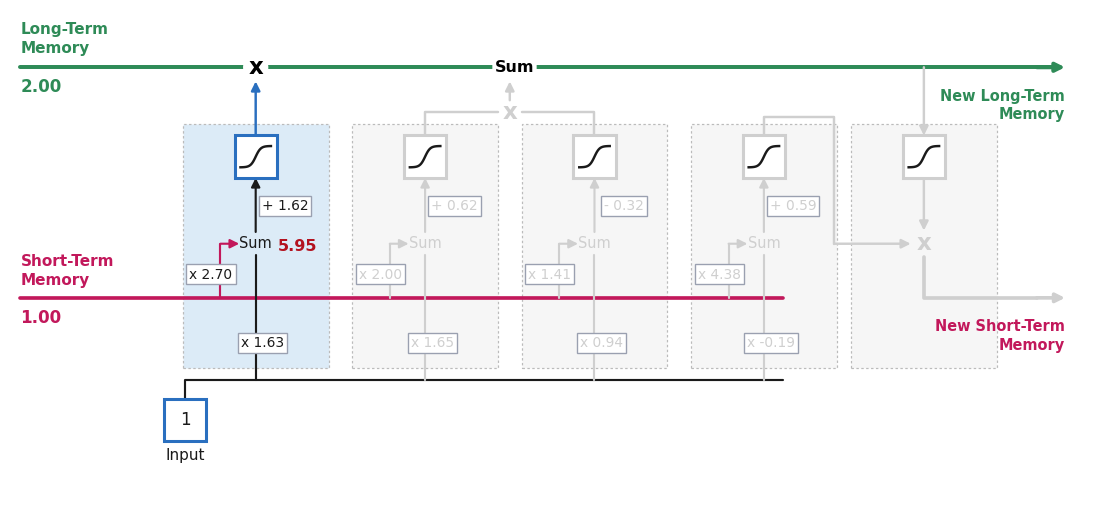

In [50]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus="forget", show=("f_sum",))
plt.show()

### Stage 1: Out of the Sigmoid

$$f(5.95) = \frac{e^{5.95}}{e^{5.95} + 1} = \frac{383.8}{384.8} = 0.997$$

- Multiply the Long-Term Memory by it: $2 \times 0.997 = 1.99$
- We <b style="color:#73000A;">remember 99.7%</b> of the long-term memory. This stage reduced it by a little bit

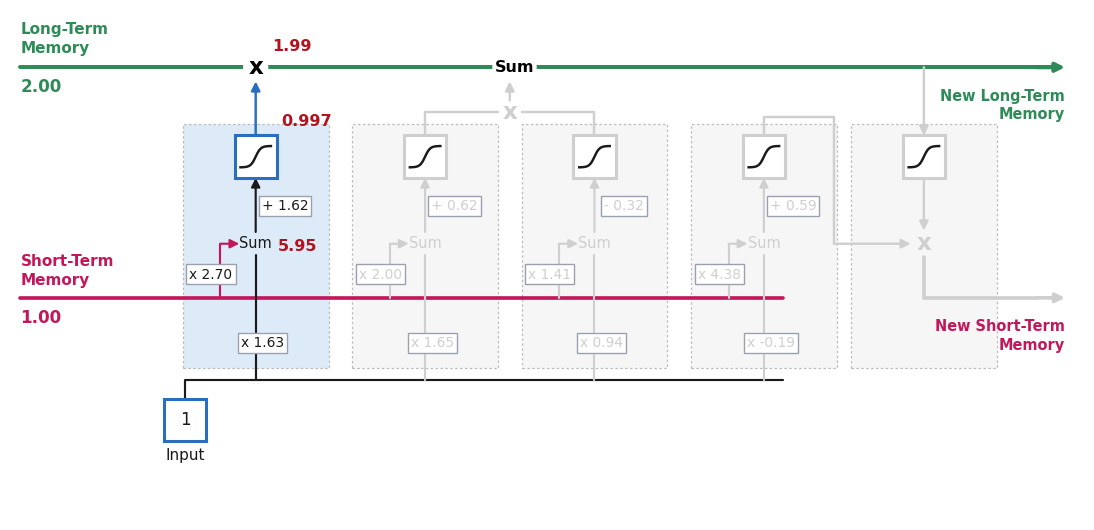

In [51]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus="forget", show=("forget",))
plt.show()

### Stage 1 With an Input of $-10$

$$(1 \times 2.70) + (-10 \times 1.63) + 1.62 = -11.98 \qquad f(-11.98) = 0.00$$

- $2 \times 0 = 0$: the long-term memory would be <b style="color:#73000A;">completely forgotten</b>
- Because the sigmoid turns any input into a number between 0 and 1, its output decides <b style="color:#73000A;">what percentage of the long-term memory is remembered</b>

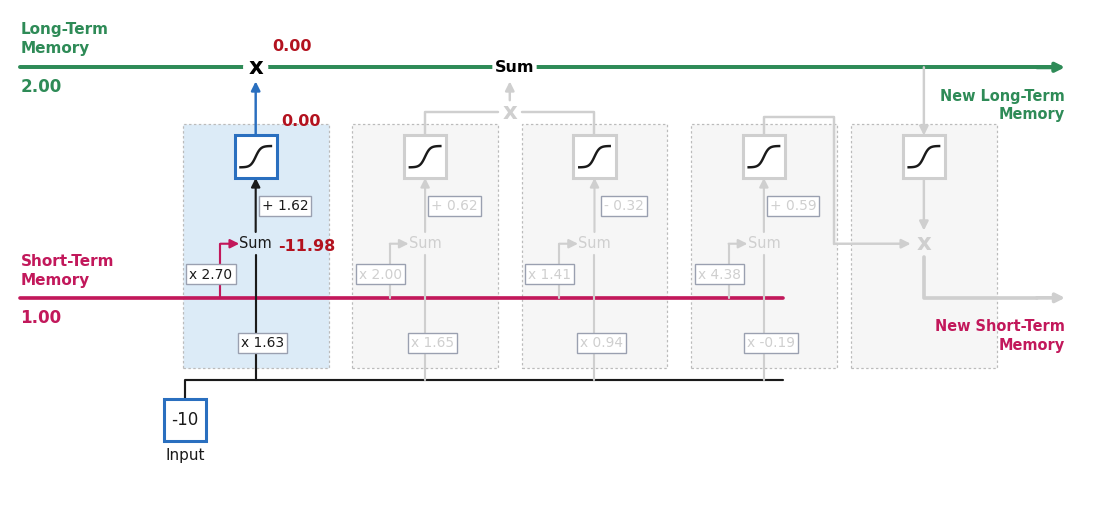

In [52]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, -10, focus="forget", show=("forget",))
plt.show()

### The Forget Gate

- So the first stage decides <b style="color:#73000A;">% Long-Term To Remember</b>
- Even though it decides what to remember, it is usually called the <b style="color:#73000A;">Forget Gate</b>

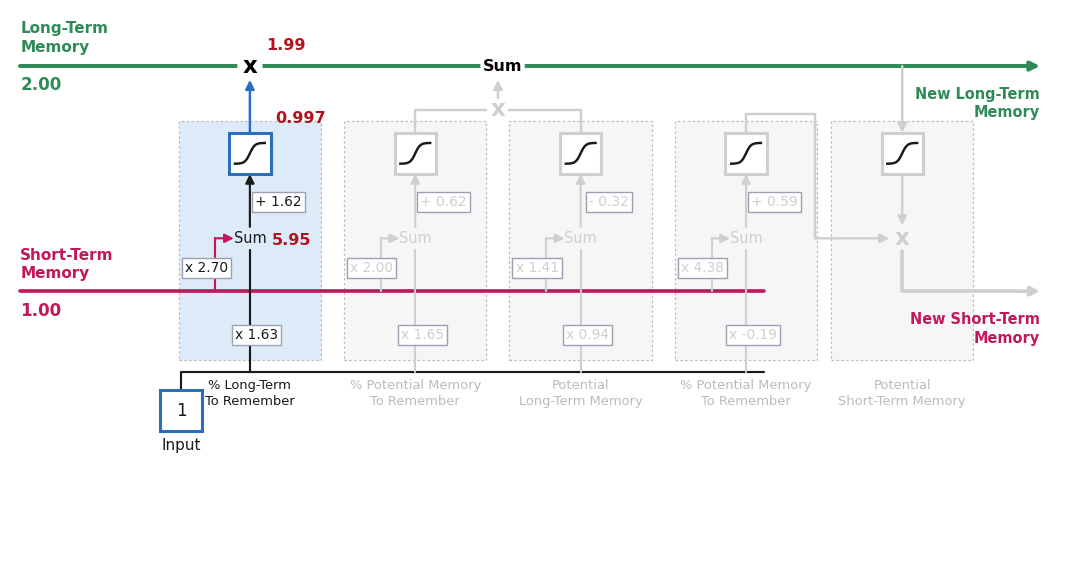

In [53]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus="forget", show=("forget",), labels=True)
plt.show()

### Stage 2: Two Blocks

- Back to an input of 1
- The block on the right combines the Short-Term Memory and the Input into a <b style="color:#73000A;">Potential Long-Term Memory</b>
- The block on the left decides <b style="color:#73000A;">what percentage</b> of that potential memory to add to the Long-Term Memory

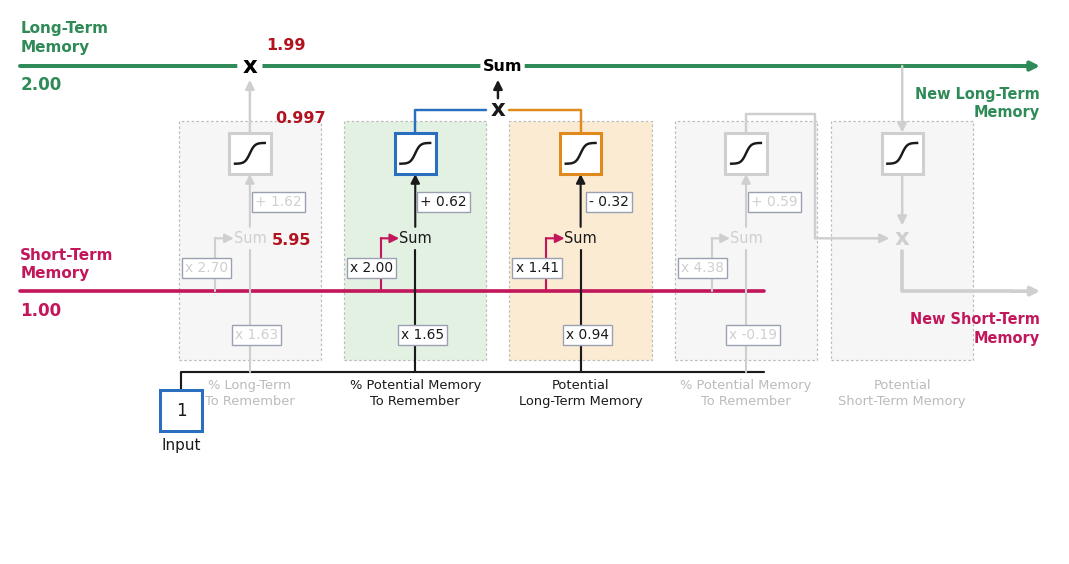

In [54]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("remember", "potential"), show=("forget",), labels=True)
plt.show()

### The Potential Long-Term Memory

- Start with the block furthest to the right:

$$(1 \times 1.41) + (1 \times 0.94) + (-0.32) = 2.03$$

$$\tanh(2.03) = \frac{e^{2.03} - e^{-2.03}}{e^{2.03} + e^{-2.03}} = 0.97$$

- With an input of 1, the tanh gives an output <b style="color:#73000A;">close to 1</b>

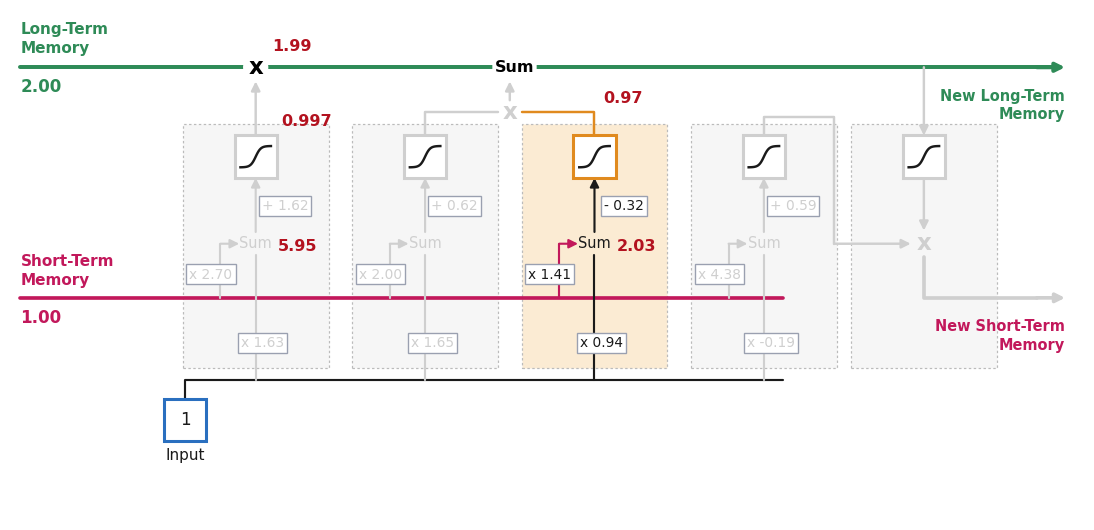

In [55]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus="potential", show=("forget", "p_sum", "p"))
plt.show()

### The Potential Memory With an Input of $-10$

$$(1 \times 1.41) + (-10 \times 0.94) + (-0.32) = -8.31 \qquad \tanh(-8.31) = -1.00$$

- Tanh turns any input into a number between $-1$ and $1$, so a potential memory can push the long-term memory <b style="color:#73000A;">either way</b>

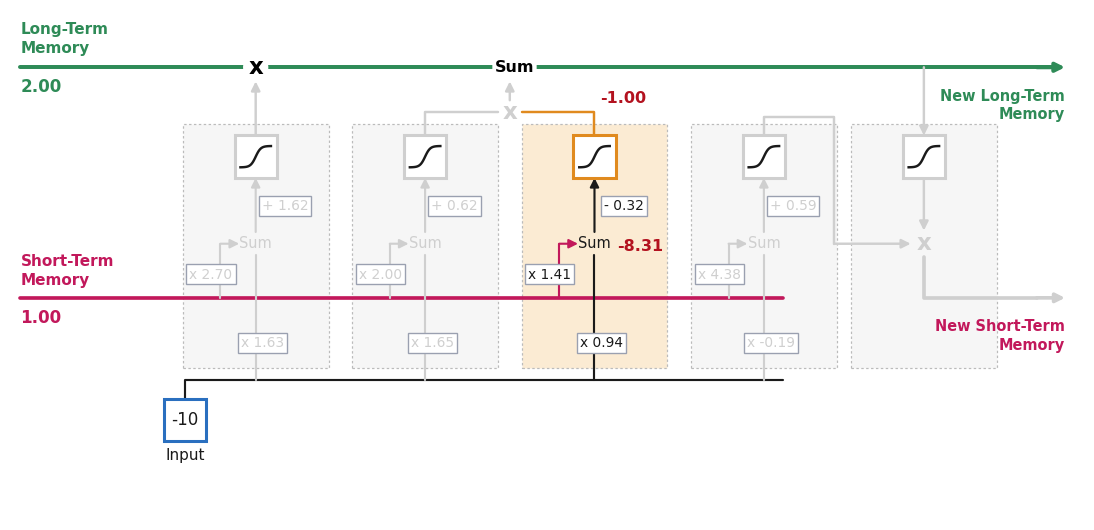

In [56]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, -10, focus="potential", show=("p_sum", "p"))
plt.show()

### % Potential Memory To Remember

- Back to an input of 1. How much of the potential memory 0.97 to save? The <b style="color:#73000A;">same method</b> as stage 1:

$$(1 \times 2.00) + (1 \times 1.65) + 0.62 = 4.27 \qquad f(4.27) = \frac{e^{4.27}}{e^{4.27} + 1} = 0.99$$

- Nearly all of the potential memory is kept

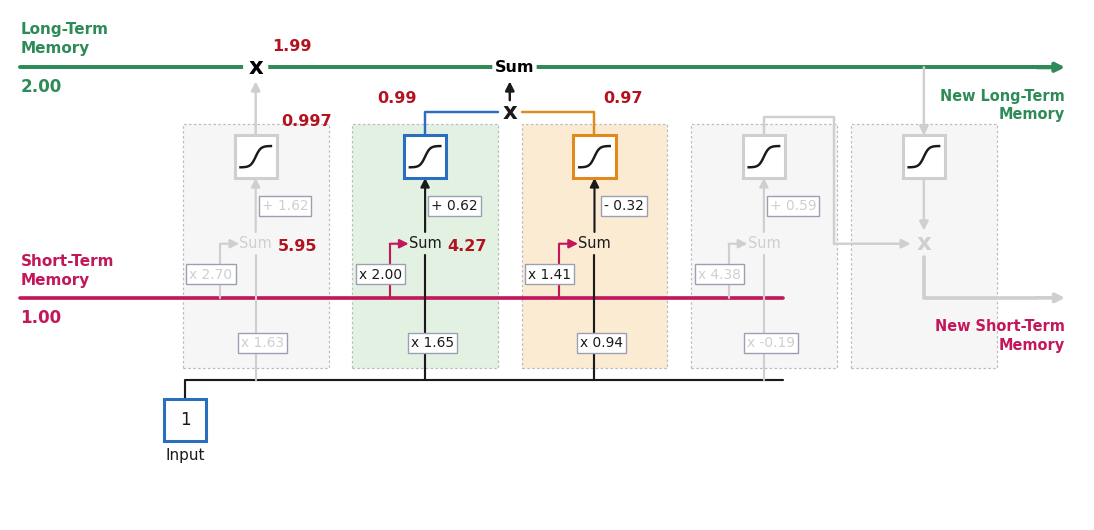

In [57]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("remember", "potential"), show=("forget", "r_sum", "r", "p"))
plt.show()

### A New Long-Term Memory

$$0.99 \times 0.97 = 0.96$$

- Add it to the scaled long-term memory: $1.99 + 0.96 =$ <b style="color:#73000A;">2.95</b>, the <b style="color:#73000A;">New Long-Term Memory</b>

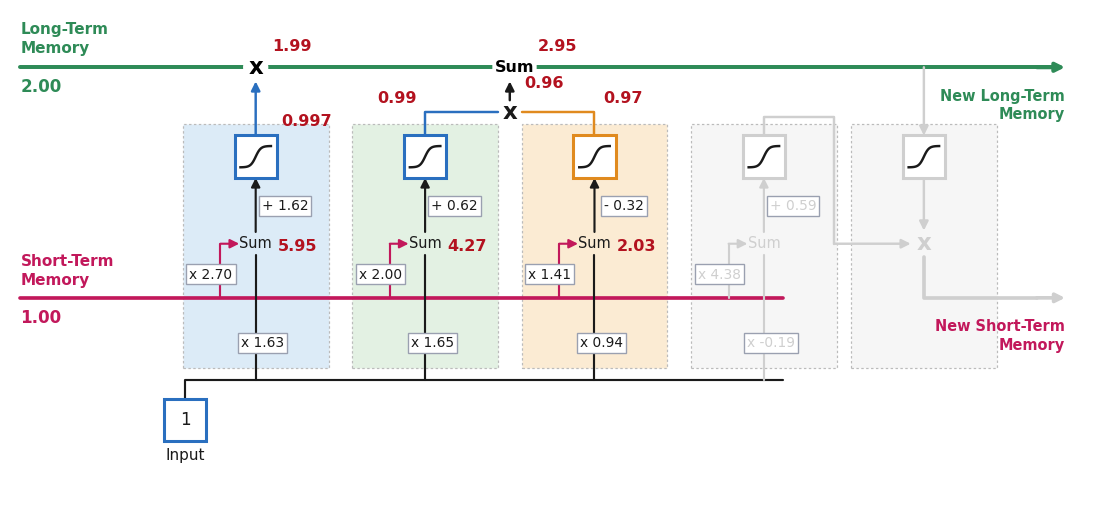

In [58]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("forget", "remember", "potential"), show=("forget", "input"))
plt.show()

### Stage 2 With an Input of $-10$

$$(1 \times 2.00) + (-10 \times 1.65) + 0.62 = -13.88 \qquad f(-13.88) = 0.00$$

- $0.00 \times -1.00 = 0$: we would <b style="color:#73000A;">not add anything</b> to the long-term memory

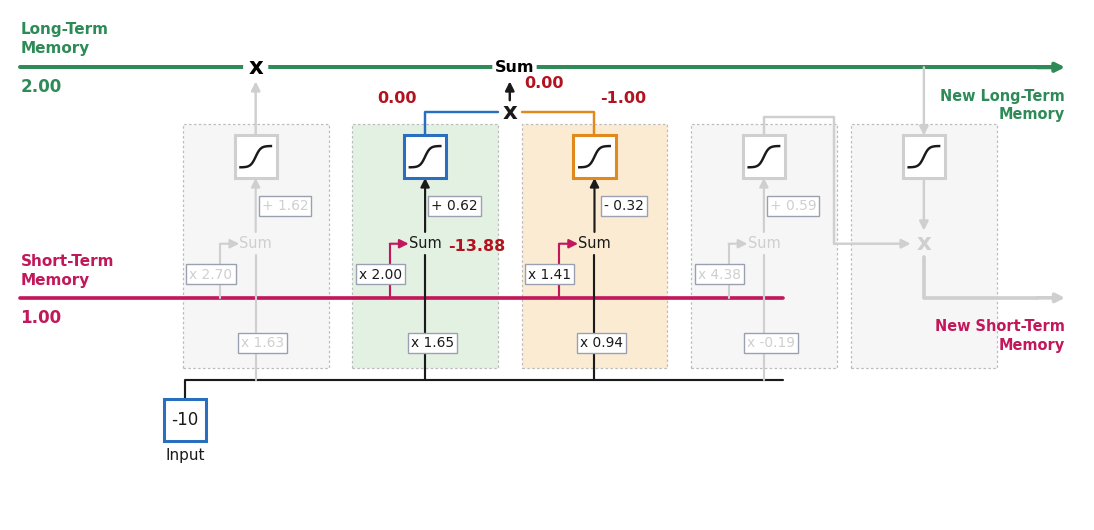

In [59]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, -10, focus=("remember", "potential"), show=("r_sum", "r", "p", "added"))
plt.show()

### The Input Gate

- Stage 2 decides how to update the long-term memory
- It is usually called the <b style="color:#73000A;">Input Gate</b>

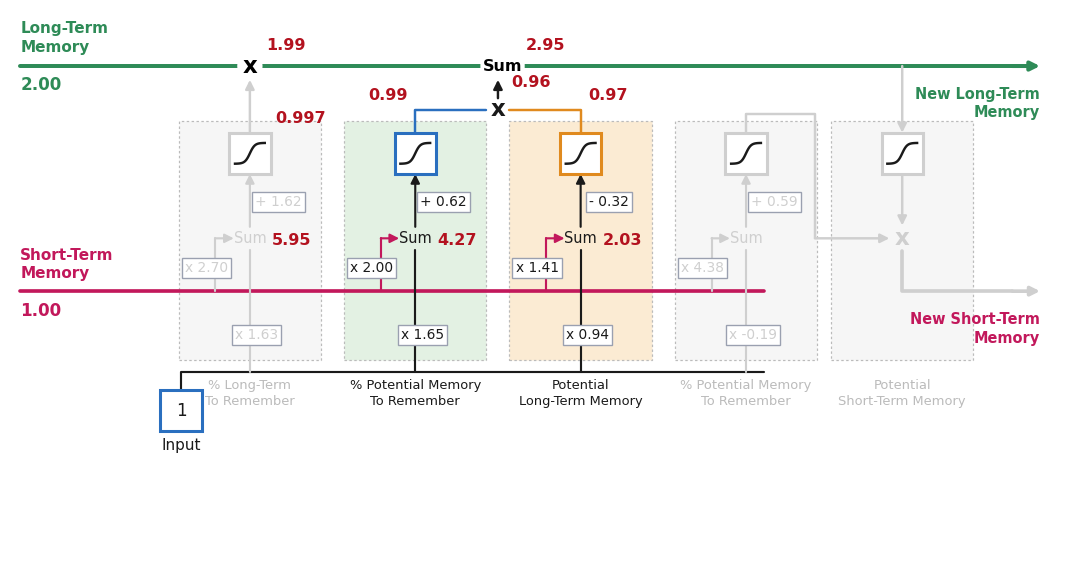

In [60]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("remember", "potential"), show=("forget", "input"), labels=True)
plt.show()

### Stage 3: A New Short-Term Memory

- Made in a way very similar to the new long-term memory
- The block on the right makes a <b style="color:#73000A;">Potential Short-Term Memory</b> from the new long-term memory:

$$\tanh(2.95) = 0.99$$

- The block on the left decides how much of it to pass on

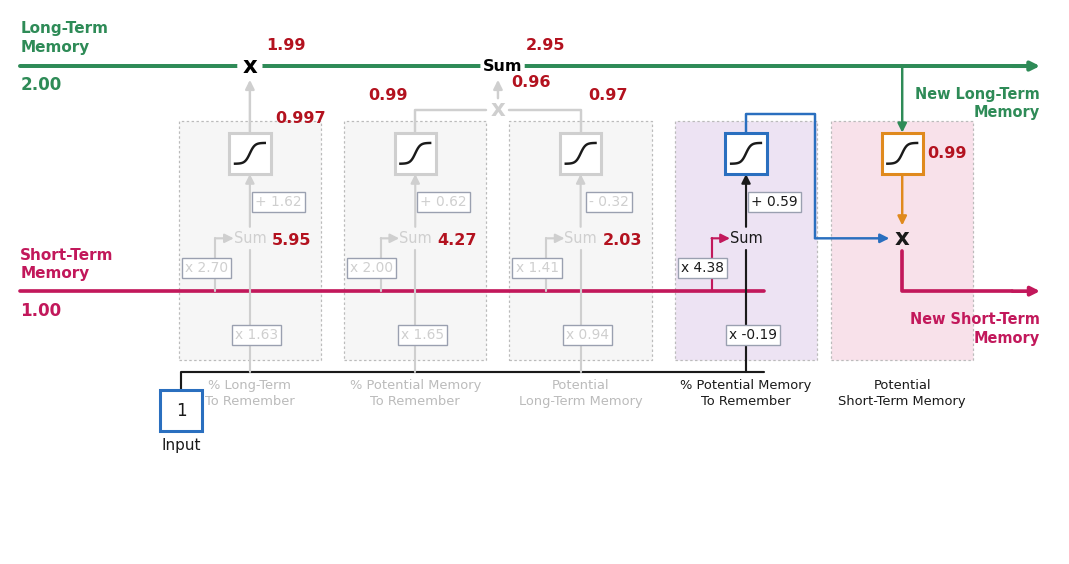

In [61]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("output", "final"), show=("forget", "input", "tanh"), labels=True)
plt.show()

### % Potential Memory To Remember, Again

- The same method a third time:

$$(1 \times 4.38) + (1 \times -0.19) + 0.59 = 4.78 \qquad f(4.78) = 0.99$$

- In all three cases, a <b style="color:#73000A;">sigmoid</b> decides what percent the LSTM remembers

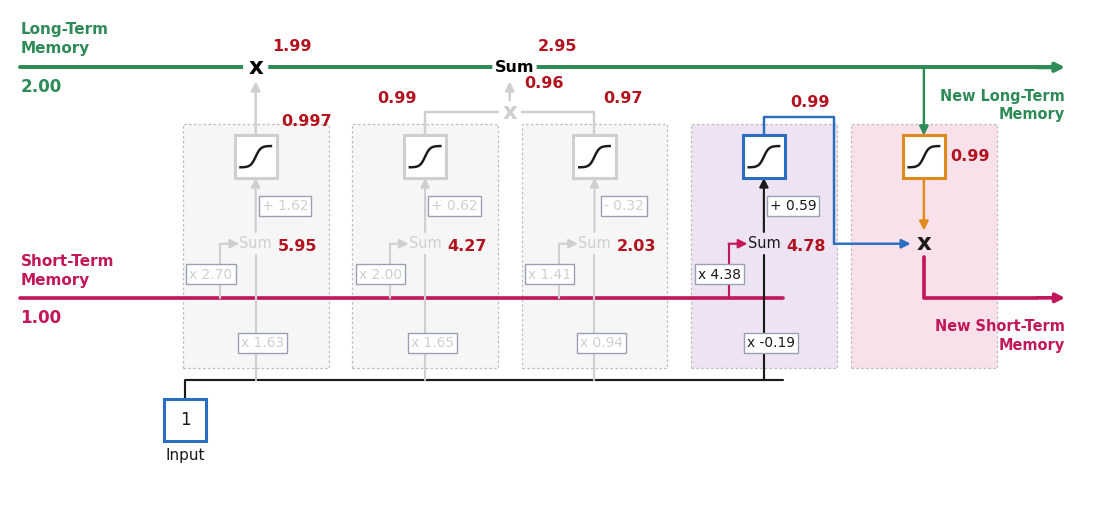

In [62]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, focus=("output", "final"), show=("forget", "input", "o_sum", "o", "tanh"))
plt.show()

### The New Short-Term Memory

$$0.99 \times 0.99 = 0.98$$

- <b style="color:#73000A;">0.98</b> is the New Short-Term Memory
- It is also the <b style="color:#73000A;">output</b> of the entire LSTM unit
- So this stage is called the <b style="color:#73000A;">Output Gate</b>

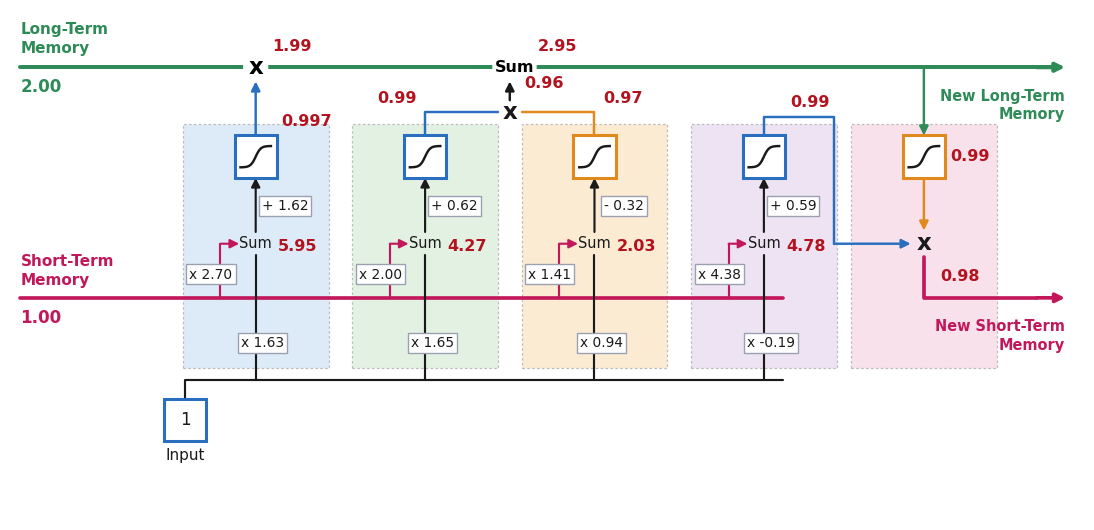

In [63]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 2, 1, 1, show=("all",))
plt.show()

### Putting Everything Together

- An LSTM unit combines a Long-Term Memory, a Short-Term Memory and an Input value
- It makes a <b style="color:#73000A;">New Long-Term Memory</b> (2 became 2.95) and a <b style="color:#73000A;">New Short-Term Memory</b> (1 became 0.98)
- Now let's see all three stages in action with real data

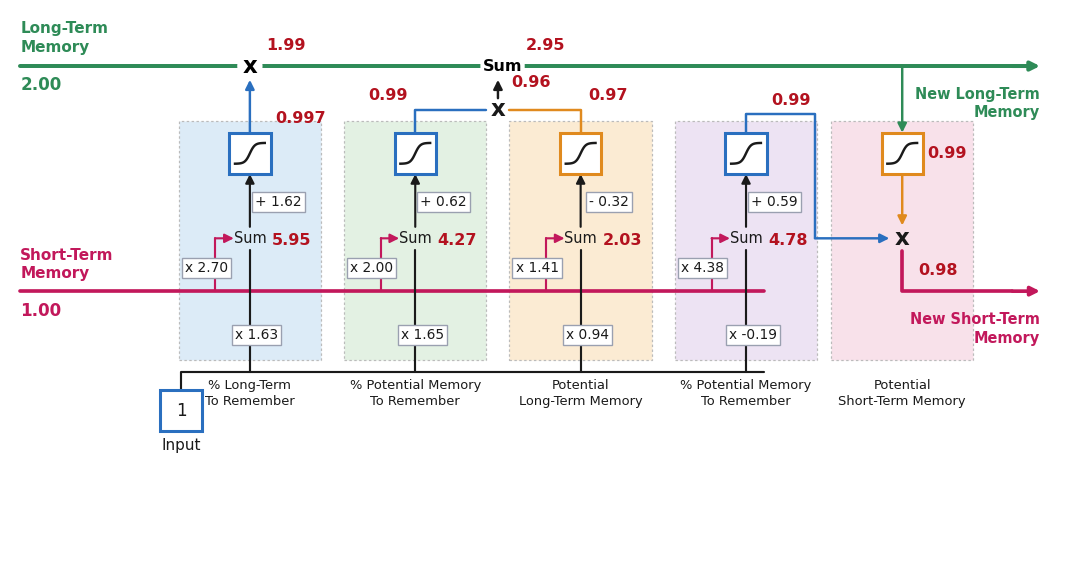

In [64]:
fig, ax = frame((13.8, 6.4), (-0.6, 22.2), (-2.4, 9.4))
lstm_unit(ax, 2, 1, 1, show=("all",), labels=True)
plt.show()

## Two Companies

- Stock values for <b style="color:#73000A;">Company A</b> and <b style="color:#73000A;">Company B</b>, recorded on days 1 to 5

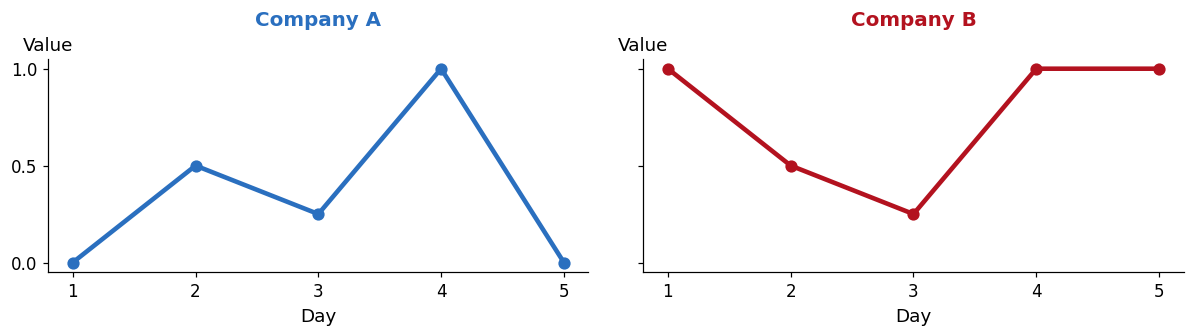

In [65]:
days = [1, 2, 3, 4, 5]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.4), dpi=110, sharey=True)
fig.patch.set_facecolor("white")
for ax, vals, name, col in ((axes[0], COMPANY_A + [0], "Company A", BLUE),
                            (axes[1], COMPANY_B + [1], "Company B", HOT)):
    ax.plot(days, vals, color=col, lw=3, marker="o", ms=7)
    ax.set_title(name, fontsize=13, color=col, weight="bold", pad=22)
    ax.set_xticks(days); ax.set_yticks([0, 0.5, 1]); ax.tick_params(labelsize=11)
    ax.set_xlabel("Day", fontsize=12)
    set_top_ylabel(ax, "Value", fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### Only Day 1 and Day 5 Differ

- On <b style="color:#73000A;">day 1</b>, Company A is at 0 and Company B is at 1
- On <b style="color:#73000A;">day 5</b>, Company A returns to 0 and Company B returns to 1
- On days 2, 3 and 4 both companies have the same values
- We want the LSTM to <b style="color:#73000A;">remember what happened on day 1</b> so it can predict day 5. Run days 1 to 4 through an unrolled LSTM

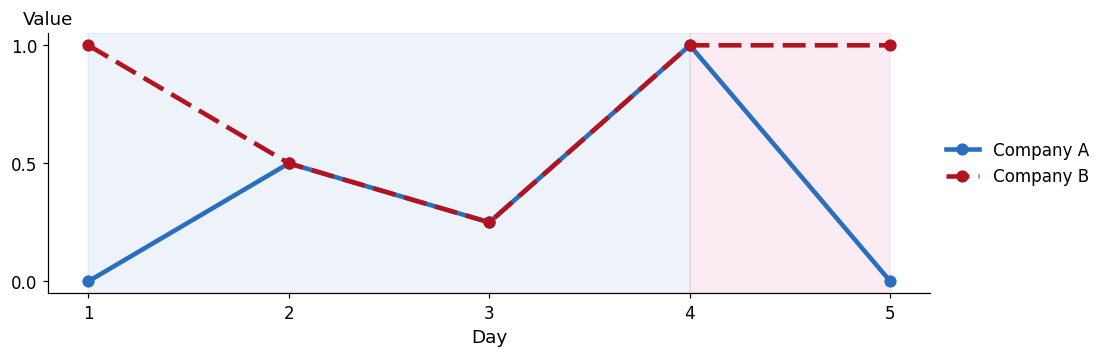

In [66]:
fig, ax = plt.subplots(figsize=(10.4, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.axvspan(1, 4, color=BLUE, alpha=0.08)
ax.axvspan(4, 5, color=PINK, alpha=0.08)
ax.plot(days, COMPANY_A + [0], color=BLUE, lw=3, marker="o", ms=7, label="Company A")
ax.plot(days, COMPANY_B + [1], color=HOT, lw=3, marker="o", ms=7, ls=(0, (5, 2)), label="Company B")
ax.set_xticks(days); ax.set_yticks([0, 0.5, 1]); ax.tick_params(labelsize=11)
ax.set_xlabel("Day", fontsize=12)
set_top_ylabel(ax, "Value", fontsize=12)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=11, frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### Company A, Day 1

- Start both memories at <b style="color:#73000A;">0</b>. That doesn't mean the LSTM has no memory, only that the memories it has are 0
- Plug in day 1's value, <b style="color:#73000A;">0</b>, and do the math with the same weights and biases:
    - $f(1.62) = 0.83$, and $0 \times 0.83 = 0$
    - $f(0.62) = 0.65$, $\tanh(-0.32) = -0.31$, and $0.65 \times -0.31 = -0.20$
    - New Long-Term Memory: $0 + (-0.20) =$ <b style="color:#73000A;">$-0.20$</b>
    - $f(0.59) = 0.64$, $\tanh(-0.20) = -0.20$, New Short-Term Memory $0.64 \times -0.20 =$ <b style="color:#73000A;">$-0.13$</b>

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 10px; border-radius:8px; font-weight:700; font-size:.8em;">Errata</span> &nbsp;Older printings show an input of 1 here; the published errata correct it to 0. The printed 0.03 for % Long-Term To Remember should be 0.83.

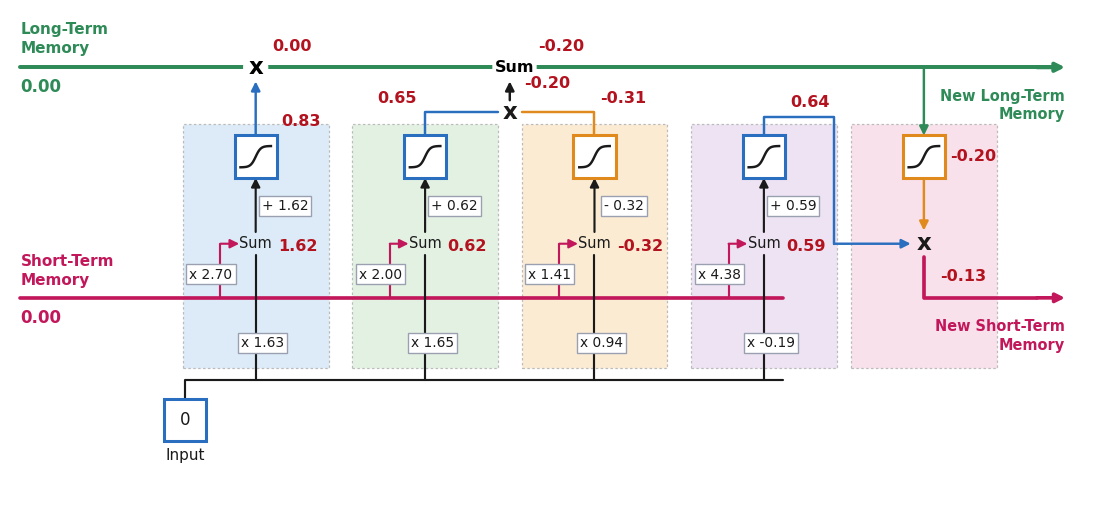

In [67]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 0, 0, 0, show=("all",))
plt.show()

### A Smaller Diagram

- The full unit takes up the whole screen, so shrink it to a box
- Long-Term Memory runs along the top, Short-Term Memory along the bottom, and the input comes in from below
- Outputs are <b style="color:#73000A;">rounded to the nearest tenth</b>: $-0.2$ and $-0.1$

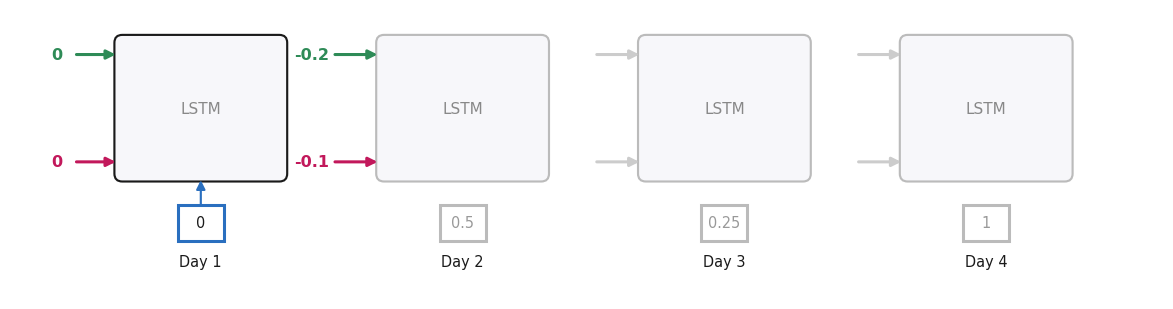

In [68]:
fig, ax = frame((13.8, 3.4), (-1.6, 16.0), (-1.8, 2.6))
lstm_chain(ax, COMPANY_A, upto=1)
plt.show()

### Company A, Days 2 and 3

- Unroll the LSTM, using the updated memories, and plug in day 2's value, <b style="color:#73000A;">0.5</b>. The same weights and biases give $-0.2$ and $-0.1$
- The LSTM reuses the same weights and biases so it can handle data sequences of <b style="color:#73000A;">different lengths</b>
- Unroll again and plug in day 3's value, <b style="color:#73000A;">0.25</b>: $-0.3$ and $-0.2$

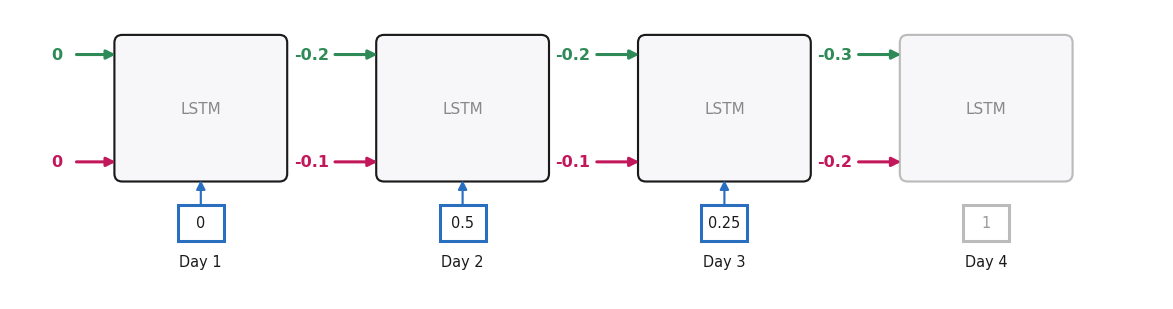

In [69]:
fig, ax = frame((13.8, 3.4), (-1.6, 16.0), (-1.8, 2.6))
lstm_chain(ax, COMPANY_A, upto=3)
plt.show()

### Company A, Day 4: The Output

- Unroll one last time and plug in day 4's value, <b style="color:#73000A;">1</b>
- The final Short-Term Memory, <b style="color:#73000A;">0.0</b>, is the output of the unrolled LSTM
- It correctly predicts Company A's value for day 5
- To keep the example simple, this LSTM was only trained to predict day 5

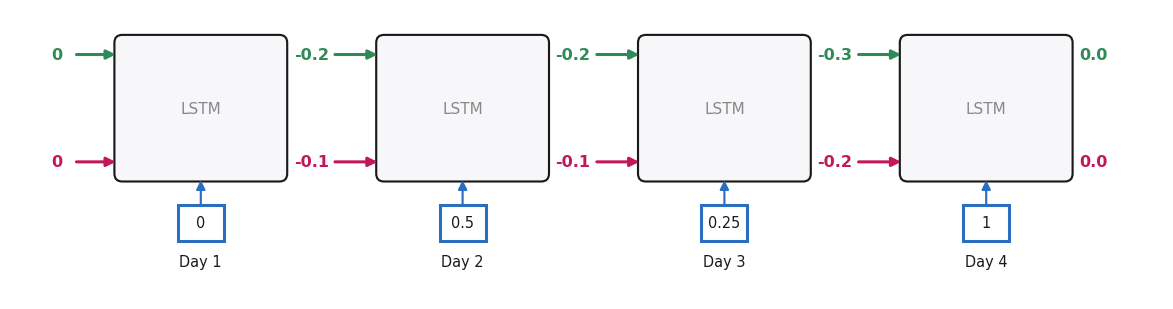

In [70]:
fig, ax = frame((13.8, 3.4), (-1.6, 16.0), (-1.8, 2.6))
lstm_chain(ax, COMPANY_A, upto=4)
plt.show()

### Company B, Day 1

- The same LSTM, the same weights and biases. Only day 1 differs, so the LSTM has to remember it
- Memories start at 0, and day 1's value is <b style="color:#73000A;">1</b>:
    - $f(3.25) = 0.96$, and $0 \times 0.96 = 0$
    - $f(2.27) = 0.91$, $\tanh(0.62) = 0.55$, and $0.91 \times 0.55 = 0.50$: New Long-Term Memory <b style="color:#73000A;">0.50</b>
    - $f(0.40) = 0.60$, $\tanh(0.50) = 0.46$, New Short-Term Memory $0.60 \times 0.46 =$ <b style="color:#73000A;">0.28</b>

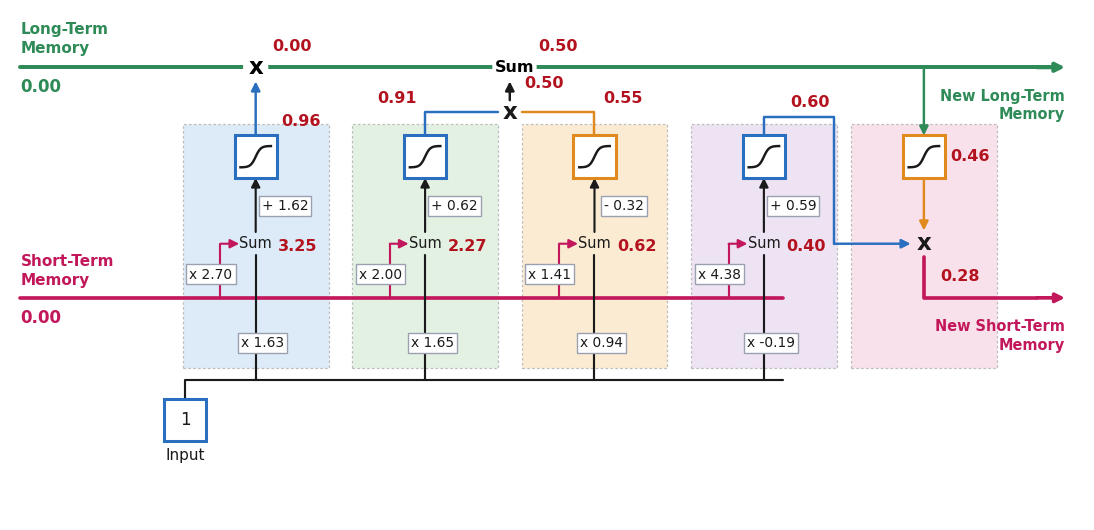

In [71]:
fig, ax = frame((13.8, 6.0), (-0.6, 22.2), (-1.4, 9.4))
lstm_unit(ax, 0, 0, 1, show=("all",))
plt.show()

### Company B, Days 2 to 4

- Unroll and do the math with the remaining values: 0.5, 0.25 and 1
- The final Short-Term Memory, <b style="color:#73000A;">1.0</b>, is the output
- It correctly predicts Company B's value for day 5

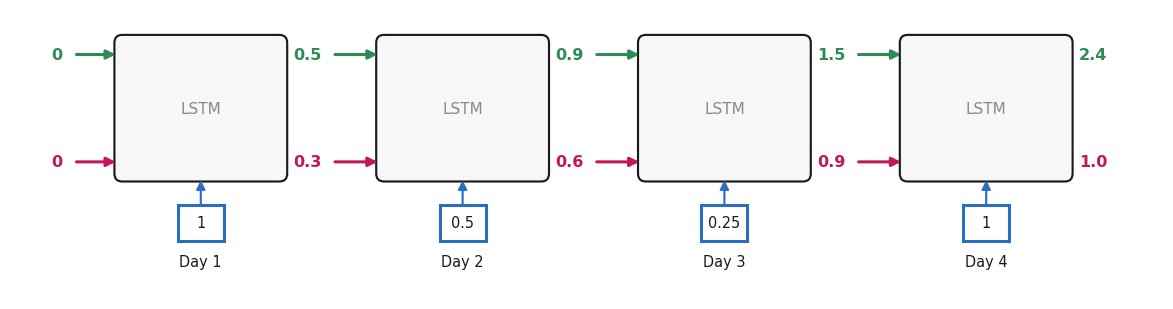

In [72]:
fig, ax = frame((13.8, 3.4), (-1.6, 16.0), (-1.8, 2.6))
lstm_chain(ax, COMPANY_B, upto=4)
plt.show()

### Day 1, Carried Forward

- Days 2, 3 and 4 were identical, so the difference on day 5 was <b style="color:#73000A;">carried from day 1</b>
- The long-term memory ends at 0.0 for Company A and 2.4 for Company B
- Separate paths for long- and short-term memories let LSTMs reduce the vanishing/exploding gradient problem, so we can unroll them <b style="color:#73000A;">more times</b> than a basic RNN

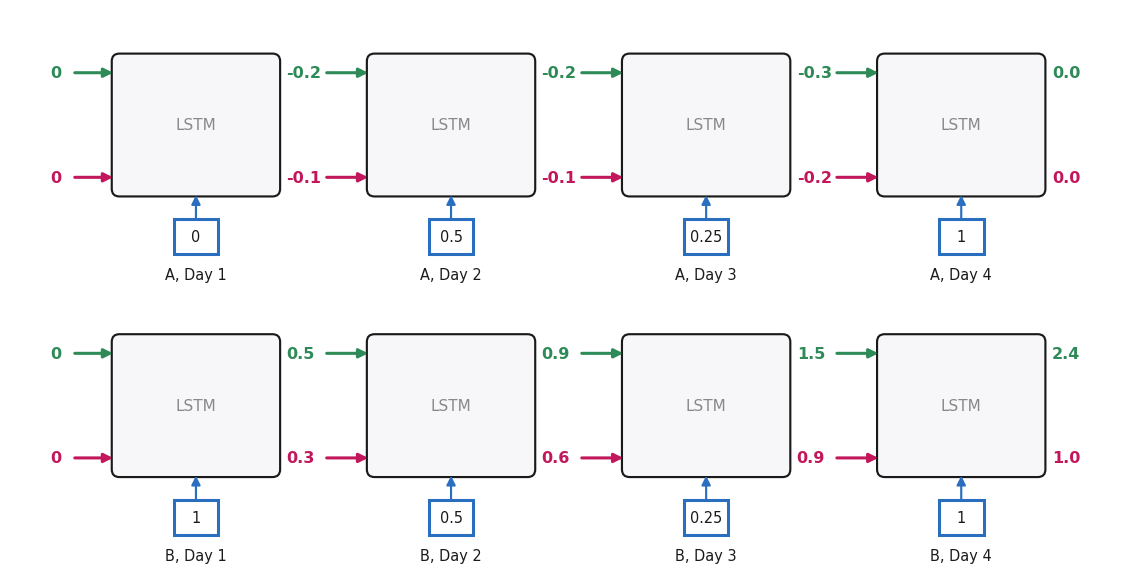

In [73]:
fig, ax = frame((13.8, 6.4), (-1.6, 16.0), (-5.6, 2.9))
lstm_chain(ax, COMPANY_A, y0=0.0, labels=["A, Day 1", "A, Day 2", "A, Day 3", "A, Day 4"])
lstm_chain(ax, COMPANY_B, y0=-4.4, labels=["B, Day 1", "B, Day 2", "B, Day 3", "B, Day 4"])
plt.show()

### The Names

- The Long-Term Memory is called the <b style="color:#73000A;">Cell State</b>
- The Short-Term Memory, which is what we use to make predictions, is called the <b style="color:#73000A;">Hidden State</b>
- The <b style="color:#73000A;">Forget Gate</b> calculates the percent of the Long-Term Memory to remember
- The <b style="color:#73000A;">Input Gate</b> calculates a new Potential Long-Term Memory and decides what percentage to remember
- The <b style="color:#73000A;">Output Gate</b> calculates a new Potential Short-Term Memory and decides what percentage to remember

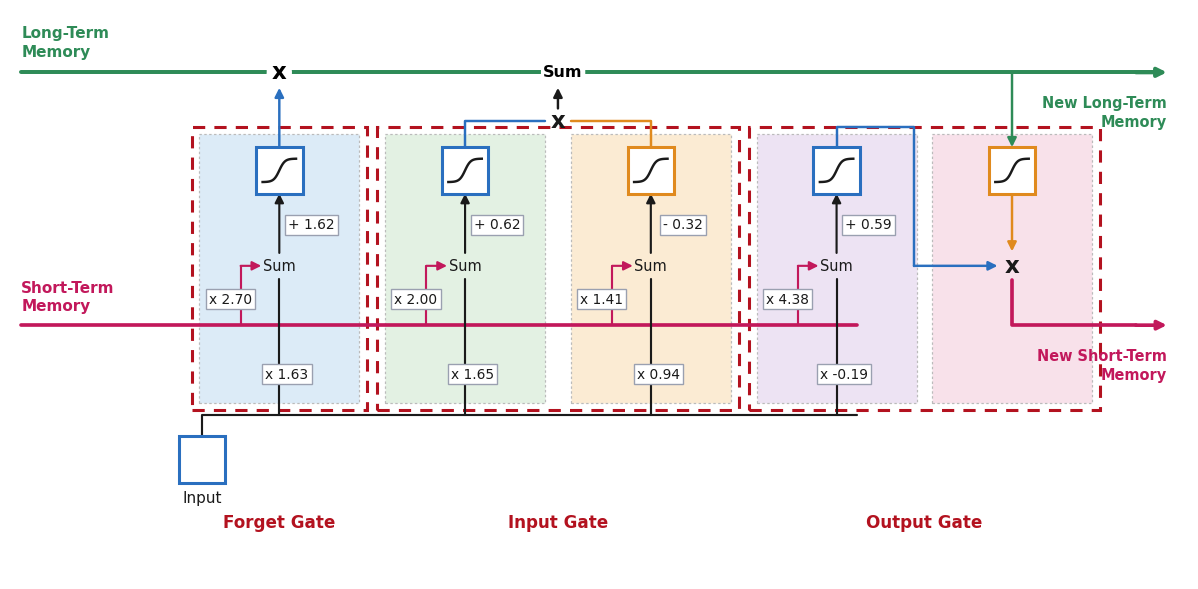

In [74]:
fig, ax = frame((13.8, 6.8), (-0.6, 22.2), (-1.6, 9.4))
lstm_unit(ax, gates=True)
plt.show()

## LSTMs in PyTorch

- `torch.sigmoid()` and `torch.tanh()` are enough to code an LSTM from scratch
- Or `nn.LSTM(input_size=1, hidden_size=1)`
    - `input_size`: how many values each time point has. One here, the stock price
    - `hidden_size`: how many outputs. One here, the predicted price
- `nn.LSTM()` starts both memories at 0 unless you pass `h_0` (the Short-Term Memory, hidden at time 0) and `c_0` (the Long-Term Memory, cell at time 0)
- Log the loss while training: if it has stopped changing, stop; if it still looks like it could improve, add epochs

In [75]:
# The deck's RNN with its weights loaded into nn.RNN, run on the four trends
import torch
import torch.nn as nn

rnn = nn.RNN(input_size=1, hidden_size=1, nonlinearity="relu", batch_first=True)
head = nn.Linear(1, 1)
with torch.no_grad():
    rnn.weight_ih_l0[:] = W1          # input weight
    rnn.weight_hh_l0[:] = W2          # the feedback loop
    rnn.bias_ih_l0[:] = B1
    rnn.bias_hh_l0[:] = 0.0
    head.weight[:] = W3               # output weight
    head.bias[:] = B2

for days in ([0, 0], [0, 0.5], [1, 0.5], [1, 1], [1, 0.5, 0.5]):
    out, h = rnn(torch.tensor(days, dtype=torch.float32).view(1, -1, 1))
    print("%-16s tomorrow %.2f" % (days, head(h[0]).item()))
print("parameters:", sum(p.numel() for p in rnn.parameters()) + 2, "whatever the number of days")

[0, 0]           tomorrow 0.00
[0, 0.5]         tomorrow 0.99
[1, 0.5]         tomorrow 0.00
[1, 1]           tomorrow 0.99
[1, 0.5, 0.5]    tomorrow 0.99
parameters: 6 whatever the number of days


In [76]:
# The deck's LSTM with its weights loaded into nn.LSTM. PyTorch stacks the
# four blocks in the order input gate, forget gate, potential memory, output gate.
lstm = nn.LSTM(input_size=1, hidden_size=1, batch_first=True)
order = [REMEMBER, FORGET, POTENTIAL, OUTPUT]
with torch.no_grad():
    lstm.weight_hh_l0[:] = torch.tensor([[w[0]] for w in order])   # times Short-Term Memory
    lstm.weight_ih_l0[:] = torch.tensor([[w[1]] for w in order])   # times the input
    lstm.bias_ih_l0[:] = torch.tensor([w[2] for w in order])
    lstm.bias_hh_l0[:] = 0.0

for name, days in (("Company A", COMPANY_A), ("Company B", COMPANY_B)):
    out, (h_n, c_n) = lstm(torch.tensor(days).view(1, -1, 1))
    print("%s  long-term (c_n) %.3f   short-term (h_n), the prediction %.3f" % (name, c_n.item(), h_n.item()))

Company A  long-term (c_n) 0.015   short-term (h_n), the prediction 0.006
Company B  long-term (c_n) 2.409   short-term (h_n), the prediction 0.969


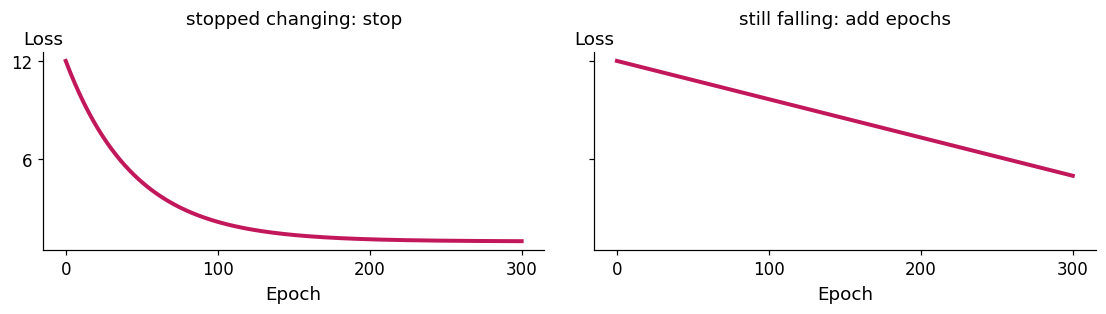

In [77]:
# Two loss curves: one that has flattened (stop) and one still falling (add epochs)
ep = np.arange(0, 301)
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.2), dpi=110, sharey=True)
fig.patch.set_facecolor("white")
for ax, loss, title in ((axes[0], 1 + 11 * np.exp(-ep / 45), "stopped changing: stop"),
                        (axes[1], 12 - 7 * ep / 300, "still falling: add epochs")):
    ax.plot(ep, loss, color=PINK, lw=2.6)
    ax.set_title(title, fontsize=12, pad=18)
    ax.set_xticks([0, 100, 200, 300]); ax.set_yticks([6, 12]); ax.tick_params(labelsize=11)
    ax.set_xlabel("Epoch", fontsize=12)
    set_top_ylabel(ax, "Loss", fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

### Earlier PyTorch Demos

A toy rule, $y_t = x_{t-1} + x_t$, learned by a plain RNN and by an LSTM, and the shapes `nn.LSTM` hands back.

In [78]:
import torch
import torch.nn as nn
import torch.optim as optim

# Toy rule: y_t = x_{t-1} + x_t
torch.manual_seed(42)
n_seq = 200
seq_len = 10

# Generate sequences following the toy rule
X_train = torch.randn(n_seq, seq_len, 1)
Y_train = torch.zeros(n_seq, seq_len)
for i in range(seq_len):
    if i >= 1:
        Y_train[:, i] = X_train[:, i-1, 0] + X_train[:, i, 0]
    else:
        Y_train[:, i] = X_train[:, i, 0]

In [79]:
# Build and train a small RNN
model = nn.RNN(input_size=1, hidden_size=8, batch_first=True)
linear_head = nn.Linear(8, 1)
optimizer = optim.Adam(list(model.parameters()) + list(linear_head.parameters()), lr=0.01)
criterion = nn.MSELoss()

losses = []
for epoch in range(100):
    optimizer.zero_grad()
    h = torch.zeros(1, n_seq, 8)

    # Forward pass through sequence
    outputs, _ = model(X_train, h)

    # Predict output at each step
    predictions = linear_head(outputs).squeeze(-1)

    loss = criterion(predictions, Y_train)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:3d}  Loss {loss.item():.4f}")

print(f"\nFinal loss: {losses[-1]:.6f}")

Epoch  50  Loss 0.0769
Epoch 100  Loss 0.0343

Final loss: 0.034300


In [80]:
# Retrain with LSTM on the same toy sequence problem
torch.manual_seed(42)
lstm_model = nn.LSTM(input_size=1, hidden_size=8, batch_first=True)
lstm_head = nn.Linear(8, 1)
optimizer_lstm = optim.Adam(list(lstm_model.parameters()) + list(lstm_head.parameters()), lr=0.01)

lstm_losses = []
for epoch in range(100):
    optimizer_lstm.zero_grad()
    h = torch.zeros(1, n_seq, 8)
    c = torch.zeros(1, n_seq, 8)

    # Forward pass through sequence
    outputs, _ = lstm_model(X_train, (h, c))

    # Predict output at each step
    predictions = lstm_head(outputs).squeeze(-1)

    loss = criterion(predictions, Y_train)
    loss.backward()
    optimizer_lstm.step()

    lstm_losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:3d}  Loss {loss.item():.4f}")

print(f"\nFinal LSTM loss: {lstm_losses[-1]:.6f}")
print(f"Final RNN loss:  {losses[-1]:.6f}")

Epoch  50  Loss 0.1416
Epoch 100  Loss 0.0214

Final LSTM loss: 0.021388
Final RNN loss:  0.034300


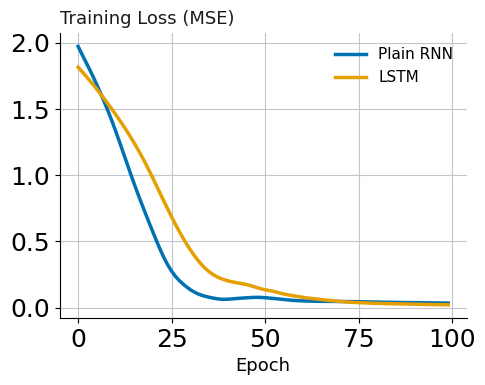

In [81]:
# Plot both loss curves
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.set_facecolor('white')
ax.grid(True, color='#C4C4D0', lw=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

ax.plot(losses, color='#0072B2', lw=2.5, label='Plain RNN')
ax.plot(lstm_losses, color='#E69F00', lw=2.5, label='LSTM')
ax.set_xlabel('Epoch', fontsize=13)
ax.text(0, 1.02, 'Training Loss (MSE)', transform=ax.transAxes, ha='left',
        va='bottom', fontsize=13, color='#1A1A1A')
ax.legend(loc='upper right', fontsize=11, frameon=False)
plt.tight_layout()
plt.show()

In [82]:
torch.manual_seed(0)
rnn4 = nn.RNN(input_size=1, hidden_size=4, batch_first=True)

# the same model, two sequences of different lengths
nine_days = torch.rand(1, 9, 1)
five_days = torch.rand(1, 5, 1)

for name, seq in [("9 days", nine_days), ("5 days", five_days)]:
    output, hidden = rnn4(seq)
    print(f"{name}: output {tuple(output.shape)}, final summary {tuple(hidden.shape)}")

n_params = sum(p.numel() for p in rnn4.parameters())
print("parameters (identical for both):", n_params)

9 days: output (1, 9, 4), final summary (1, 1, 4)
5 days: output (1, 5, 4), final summary (1, 1, 4)
parameters (identical for both): 28


### The Names on the Wires

| In this lecture | In the literature | In PyTorch |
|---|---|---|
| Long-Term Memory | cell state $c_t$ | `c_n` |
| Short-Term Memory, the output | hidden state $h_t$ | `h_n` |
| % Long-Term To Remember | forget gate $f_t$ | inside `nn.LSTM` |
| % Potential Memory To Remember | input gate $i_t$ | inside `nn.LSTM` |
| % Potential Memory To Remember, again | output gate $o_t$ | inside `nn.LSTM` |

In [83]:
torch.manual_seed(0)
lstm4 = nn.LSTM(input_size=1, hidden_size=4, batch_first=True)
rnn4 = nn.RNN(input_size=1, hidden_size=4, batch_first=True)

series = torch.rand(1, 9, 1)                  # nine days of prices
output, (h_n, c_n) = lstm4(series)

print("output        :", tuple(output.shape))
print("short-term h_n:", tuple(h_n.shape))
print("long-term  c_n:", tuple(c_n.shape))
print("LSTM parameters:", sum(p.numel() for p in lstm4.parameters()))
print("RNN  parameters:", sum(p.numel() for p in rnn4.parameters()))

output        : (1, 9, 4)
short-term h_n: (1, 1, 4)
long-term  c_n: (1, 1, 4)
LSTM parameters: 112
RNN  parameters: 28


## Key Ideas

- A recurrent network has a <b style="color:#73000A;">feedback loop</b>. Unrolled, it is one copy per day, every copy sharing the same weights and biases, so any number of days fits
- With weights 1.8, $-0.5$ and 1.1, the four StatLand trends come out right: 0, 1, 0, 1
- <b style="color:#73000A;">Backpropagation through time</b>: each input is multiplied by $W_2$ once per unroll, so the derivative has $W_2$ raised to that power
- $W_2 = 0.5$: 21 days back counts 0.000001, and the gradient <b style="color:#73000A;">vanishes</b>. $W_2 = 2$: 1,048,576, and it <b style="color:#73000A;">explodes</b>
- An <b style="color:#73000A;">LSTM</b> keeps a Long-Term Memory with no weights on it, and a Short-Term Memory that has weights
- <b style="color:#73000A;">Forget gate</b>: % of the long-term memory to remember. <b style="color:#73000A;">Input gate</b>: a potential memory and how much to add. <b style="color:#73000A;">Output gate</b>: the new short-term memory, which is also the output
- The same weights carry day 1 forward and predict 0 for Company A and 1 for Company B